# THG-Zielwert – interne Szenarien- und Sektorvergleichsrechnung

**Diskussionsstand 11.11.2026 · historische Referenz / Alaux FOA 37 % / PEQ Gebäude + MIV 50 %**

Parametrische Vergleichsrechnung. Die Kernergebnisse werden im letzten gemeinsamen Diagramm dargestellt.

**Datengrundlagen:** Schneider et al. (2025), Tab. A1 · Steininger et al. (2022) · Lamboll et al. (2023) · Alaux et al. (2023) · Umweltbundesamt, Inventar 2026 / NowCast 2025.

**Dateien:** `thg_nationale_klimabudgets.csv`, `thg_globale_budgets_kontext.csv`, `thg_historische_emissionen_AT.csv`, `thg_historische_aggregatannahmen.csv`.

Die Werte und Annahmen werden in den nachfolgenden Eingabezellen gewählt; Änderungen danach mit **Run All** berechnen.

## Ablauf der neuen Kalibrierung

```{mermaid}
%%| fig-width: 11
%%| fig-height: 5.5
flowchart TB
    B["Globales Restbudget ab 2023<br/>Lamboll oder Alaux<br/>Temperaturziel und Wahrscheinlichkeit"]
    A["Pro-Kopf-Allokation EPC<br/>0,10 % oder AT/Welt 2023"]
    N["AT-Budget ab Referenzjahr [Mt CO2]"]
    U["UBA: Emissionen Referenzjahr bis t-1<br/>CO2e-Näherung"]
    R["Restbudget Österreich im Bewertungsjahr"]
    S["Natürliche Senken: 0 oder 1 t pro Person und Jahr<br/>über verbleibende Jahre"]
    F["Alaux: 37 % FOA Buildings"]
    P["PEQ: 50 % Gebäude + MIV"]
    G["Division durch nationale BGF<br/>kg CO2e je m² BGF"]
    H["Historisch: Steininger/Schneider L1–L3<br/>Ab 2025, 50 % Gebäude + MIV"]
    V["Gemeinsamer Szenarienvergleich"]
    B --> A --> N --> R
    U --> R
    R --> S
    S --> F --> G
    S --> P --> G
    G --> V
    H --> V
    classDef base fill:#e9eff7,stroke:#6b829b,color:#26384e
    classDef output fill:#dfeeea,stroke:#37927e,color:#1b5448
    class B,A,N,U,R,S,F,P,H base
    class G,V output
```

::: {.callout-note title="Bewertungsstand" collapse="true"}
Die historische Referenz wird **ab 2025** gezeigt, die neuen Szenarien im wählbaren Jahr `COMPARISON_YEAR` (Voreinstellung **2026**). Gleiche BGF und Senkenjahre erlauben eine Sensitivitätsbetrachtung, die Quellenstände bleiben separat.
:::

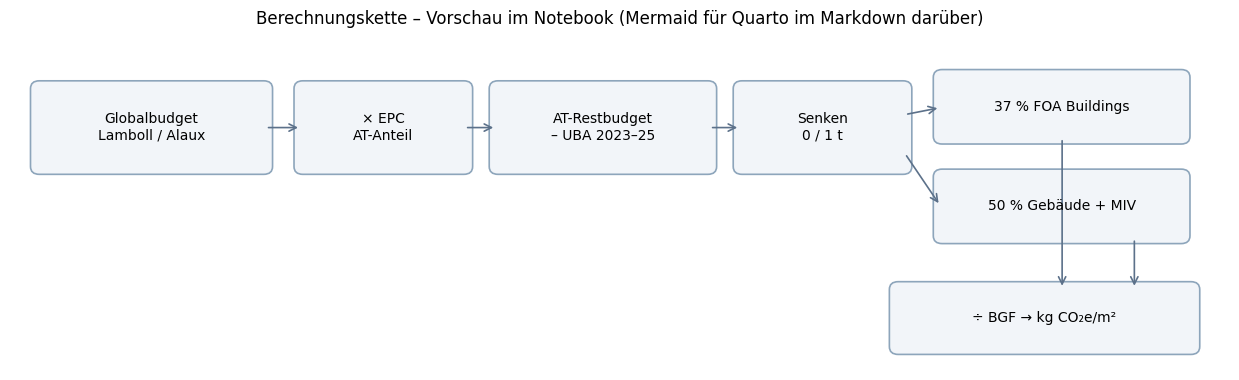

In [1]:
#| include: false
# Jupyter-Vorschau des Rechenflusses; Quarto rendert das Mermaid-Diagramm oben.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12.5, 3.9))
ax.set_xlim(0, 12.5); ax.set_ylim(0, 3.9); ax.axis('off')
boxes = [
    (0.3, 2.35, 2.3, 0.9, 'Globalbudget\nLamboll / Alaux'),
    (3.0, 2.35, 1.65, 0.9, '× EPC\nAT-Anteil'),
    (5.0, 2.35, 2.15, 0.9, 'AT-Restbudget\n– UBA 2023–25'),
    (7.5, 2.35, 1.65, 0.9, 'Senken\n0 / 1 t'),
    (9.55, 2.7, 2.45, 0.68, '37 % FOA Buildings'),
    (9.55, 1.55, 2.45, 0.68, '50 % Gebäude + MIV'),
    (9.1, 0.27, 3.0, 0.66, '÷ BGF → kg CO₂e/m²'),
]
for x,y,w,h,label in boxes:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.09',fc='#f2f5f9',ec='#8da5bb',lw=1.2))
    ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=10)
for a,b in [((2.62,2.8),(2.98,2.8)),((4.66,2.8),(4.98,2.8)),((7.17,2.8),(7.48,2.8)),
            ((9.17,2.95),(9.53,3.03)),((9.17,2.5),(9.53,1.9)),((10.78,2.68),(10.78,.94)),
            ((11.52,1.52),(11.52,.94))]:
    ax.add_patch(FancyArrowPatch(a,b,arrowstyle='->',mutation_scale=13,lw=1.2,color='#5c718a'))
ax.set_title('Berechnungskette – Vorschau im Notebook (Mermaid für Quarto im Markdown darüber)',fontsize=12)
plt.tight_layout();plt.show()

In [2]:
from __future__ import annotations
from dataclasses import dataclass, asdict
from pathlib import Path
import sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 105)
plt.rcParams.update({'figure.figsize': (9, 4.4), 'axes.grid': True, 'grid.alpha': .22, 'font.size': 10})
MODEL_VERSION = '0.4.0-intern-sektorvergleich'
SOURCE_URLS = {'S1': 'https://doi.org/10.3390/designs9060123',
               'S5': 'https://doi.org/10.1038/s41467-022-31204-8',
               'S6': 'https://doi.org/10.1038/s41558-023-01848-5',
               'S9': 'https://doi.org/10.1088/1742-6596/2600/15/152004',
               'S7': 'https://www.umweltbundesamt.at/fileadmin/site/publikationen/rep1016.pdf',
               'S8': 'https://www.umweltbundesamt.at/news260902-treibhausgas-emissionen-2025',
                'S10': 'https://data.worldbank.org/indicator/SP.POP.TOTL?locations=AT',
                'S11': 'https://data.worldbank.org/indicator/SP.POP.TOTL?locations=1W'}
print(f'Arbeitsstand {MODEL_VERSION} | Python {sys.version.split()[0]} | pandas {pd.__version__}')

Arbeitsstand 0.4.0-intern-sektorvergleich | Python 3.13.5 | pandas 2.2.3


## 1. Eingangsbudgets und historische Emissionen

Die vier CSV-Tabellen können neben dem Notebook liegen und dort angepasst werden. Ohne CSV-Dateien greifen die im Notebook eingebetteten Ausgangswerte.

In [3]:
SEED_BUDGETS = [{'budget_id': 'STEIN2022_15_NO_50', 'quelle_name': 'Steininger et al. via Schneider et al. 2025', 'temperatur': '1,5 °C', 'overshoot': 'ohne', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2022, 'national_budget_Mt': '510', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial', 'quelle_id': 'S1-A1', 'datenstatus': 'publiziert'}, {'budget_id': 'STEIN2022_15_NO_66', 'quelle_name': 'Steininger et al. via Schneider et al. 2025', 'temperatur': '1,5 °C', 'overshoot': 'ohne', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2022, 'national_budget_Mt': '280', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial', 'quelle_id': 'S1-A1', 'datenstatus': 'publiziert: L3-Referenz'}, {'budget_id': 'STEIN2022_15_YES_50', 'quelle_name': 'Steininger et al. via Schneider et al. 2025', 'temperatur': '1,5 °C', 'overshoot': 'mit', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2022, 'national_budget_Mt': '610', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial', 'quelle_id': 'S1-A1', 'datenstatus': 'publiziert'}, {'budget_id': 'STEIN2022_15_YES_66', 'quelle_name': 'Steininger et al. via Schneider et al. 2025', 'temperatur': '1,5 °C', 'overshoot': 'mit', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2022, 'national_budget_Mt': '340', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial', 'quelle_id': 'S1-A1', 'datenstatus': 'publiziert'}, {'budget_id': 'LAMBOLL2023_AT_15_50', 'quelle_name': 'Lamboll et al. (2023); AT-Allokation noch ausständig', 'temperatur': '1,5 °C', 'overshoot': 'nicht festgelegt', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'national_budget_Mt': '', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial (noch zu allokieren)', 'quelle_id': 'S6', 'datenstatus': 'offen: nationales Budget fehlt'}, {'budget_id': 'LAMBOLL2023_AT_15_66', 'quelle_name': 'Lamboll et al. (2023); AT-Allokation noch ausständig', 'temperatur': '1,5 °C', 'overshoot': 'nicht festgelegt', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2023, 'national_budget_Mt': '', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial (noch zu allokieren)', 'quelle_id': 'S6', 'datenstatus': 'offen: nationales Budget fehlt'}, {'budget_id': 'LAMBOLL2023_AT_20_50', 'quelle_name': 'Lamboll et al. (2023) – Globalbudget; EPC-Anteil nach Alaux et al. (2023)', 'temperatur': '2,0 °C', 'overshoot': 'nicht festgelegt', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'national_budget_Mt': '', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial, EPC-Allokation als Modellübertragung (keine veröffentlichte nationale Zahl)', 'quelle_id': 'S6+S9', 'datenstatus': 'Wird aus global 1.200 Gt (gerundet) × EPC 0,10 % berechnet'}, {'budget_id': 'LAMBOLL2023_AT_20_66', 'quelle_name': 'Lamboll et al. (2023); AT-Allokation noch ausständig', 'temperatur': '2,0 °C', 'overshoot': 'nicht festgelegt', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2023, 'national_budget_Mt': '', 'einheit': 'Mt CO2', 'systemgrenze': 'AT territorial (noch zu allokieren)', 'quelle_id': 'S6', 'datenstatus': 'offen: nationales Budget fehlt'}]
SEED_HIST = [{'jahr': 2022, 'reihe': 'GHG_TOTAL_EXCL_LULUCF', 'emissionen_Mt': 73.506582, 'einheit': 'Mt CO2e', 'quelle_id': 'S7', 'datenversion': 'Inventar 2026 (revidiert)', 'abgrenzung': 'ohne LULUCF, gesamte THG', 'datenstatus': 'kontext: NICHT CO2-Budget-kompatibel'}, {'jahr': 2023, 'reihe': 'GHG_TOTAL_EXCL_LULUCF', 'emissionen_Mt': 68.67406, 'einheit': 'Mt CO2e', 'quelle_id': 'S7', 'datenversion': 'Inventar 2026 (revidiert)', 'abgrenzung': 'ohne LULUCF, gesamte THG', 'datenstatus': 'kontext: NICHT CO2-Budget-kompatibel'}, {'jahr': 2024, 'reihe': 'GHG_TOTAL_EXCL_LULUCF', 'emissionen_Mt': 66.637831, 'einheit': 'Mt CO2e', 'quelle_id': 'S7', 'datenversion': 'Inventar 2026 (revidiert)', 'abgrenzung': 'ohne LULUCF, gesamte THG', 'datenstatus': 'kontext: NICHT CO2-Budget-kompatibel'}, {'jahr': 2025, 'reihe': 'GHG_TOTAL_EXCL_LULUCF', 'emissionen_Mt': 67.1, 'einheit': 'Mt CO2e', 'quelle_id': 'S8', 'datenversion': 'NowCast September 2026', 'abgrenzung': 'ohne LULUCF, THG', 'datenstatus': 'vorläufig; NICHT CO2-Budget-kompatibel'}, {'jahr': 2022, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': '', 'einheit': 'Mt CO2', 'quelle_id': 'S7', 'datenversion': 'Nachtrag erforderlich', 'abgrenzung': 'CO2-only, territorial, LULUCF-Konvention prüfen', 'datenstatus': 'offen; CO2-Jahreswert fehlt'}, {'jahr': 2023, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': '', 'einheit': 'Mt CO2', 'quelle_id': 'S7', 'datenversion': 'Nachtrag erforderlich', 'abgrenzung': 'CO2-only, territorial, LULUCF-Konvention prüfen', 'datenstatus': 'offen; CO2-Jahreswert fehlt'}, {'jahr': 2024, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': '', 'einheit': 'Mt CO2', 'quelle_id': 'S7', 'datenversion': 'Nachtrag erforderlich', 'abgrenzung': 'CO2-only, territorial, LULUCF-Konvention prüfen', 'datenstatus': 'offen; CO2-Jahreswert fehlt'}, {'jahr': 2025, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': '', 'einheit': 'Mt CO2', 'quelle_id': '', 'datenversion': 'Noch keine harmonisierte Reihe übernommen', 'abgrenzung': 'CO2-only, territorial, LULUCF-Konvention prüfen', 'datenstatus': 'offen; für 2026-Budget notwendig'}]
SEED_AGG = [{'von_jahr': 2022, 'bis_jahr': 2024, 'reihe': 'CO2_TERRITORIAL', 'emissionen_Mt': 150.0, 'einheit': 'Mt CO2', 'quelle_id': 'S1-A1', 'herleitung': 'Schneider et al. 2025, Tab. A1: 280-130 bzw. 340-190', 'hinweis': 'aggregierte historische Abzugsannahme; keine jährliche Inventarreihe'}]
SEED_GLOBAL = [{'quelle': 'Lamboll 2023', 'temperatur': '1,5 °C', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'global_budget_Gt': 250, 'einheit': 'Gt CO2', 'quelle_id': 'S6', 'hinweis': 'publiziert (Haupttext), global'}, {'quelle': 'Lamboll 2023', 'temperatur': '2,0 °C', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'global_budget_Gt': 1220, 'einheit': 'Gt CO2', 'quelle_id': 'S6', 'hinweis': 'präziser Artikelwert; im Abstract gerundet ca. 1.200 Gt'}, {'quelle': 'Lamboll 2023', 'temperatur': '2,0 °C', 'wahrscheinlichkeit_pct': 66, 'referenzjahr': 2023, 'global_budget_Gt': 940, 'einheit': 'Gt CO2', 'quelle_id': 'S6', 'hinweis': 'publiziert (Haupttext), global'}, {'quelle': 'Alaux 2023', 'temperatur': '1,5 °C', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'global_budget_Gt': 380, 'einheit': 'Gt CO2', 'quelle_id': 'S9', 'hinweis': 'Tabelle 1; eigenständiger Datenstand'}, {'quelle': 'Alaux 2023', 'temperatur': '1,5 °C', 'wahrscheinlichkeit_pct': 67, 'referenzjahr': 2023, 'global_budget_Gt': 280, 'einheit': 'Gt CO2', 'quelle_id': 'S9', 'hinweis': 'Tabelle 1; eigenständiger Datenstand'}, {'quelle': 'Alaux 2023', 'temperatur': '1,5 °C', 'wahrscheinlichkeit_pct': 83, 'referenzjahr': 2023, 'global_budget_Gt': 180, 'einheit': 'Gt CO2', 'quelle_id': 'S9', 'hinweis': 'Tabelle 1; eigenständiger Datenstand'}, {'quelle': 'Alaux 2023', 'temperatur': '1,7 °C', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'global_budget_Gt': 730, 'einheit': 'Gt CO2', 'quelle_id': 'S9', 'hinweis': 'Tabelle 1; eigenständiger Datenstand'}, {'quelle': 'Alaux 2023', 'temperatur': '1,7 °C', 'wahrscheinlichkeit_pct': 67, 'referenzjahr': 2023, 'global_budget_Gt': 580, 'einheit': 'Gt CO2', 'quelle_id': 'S9', 'hinweis': 'Tabelle 1; eigenständiger Datenstand'}, {'quelle': 'Alaux 2023', 'temperatur': '1,7 °C', 'wahrscheinlichkeit_pct': 83, 'referenzjahr': 2023, 'global_budget_Gt': 430, 'einheit': 'Gt CO2', 'quelle_id': 'S9', 'hinweis': 'Tabelle 1; eigenständiger Datenstand'}, {'quelle': 'Alaux 2023', 'temperatur': '2,0 °C', 'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023, 'global_budget_Gt': 1230, 'einheit': 'Gt CO2', 'quelle_id': 'S9', 'hinweis': 'Tabelle 1; Alaux-Wert ist nicht der Lamboll-Wert'}, {'quelle': 'Alaux 2023', 'temperatur': '2,0 °C', 'wahrscheinlichkeit_pct': 67, 'referenzjahr': 2023, 'global_budget_Gt': 1030, 'einheit': 'Gt CO2', 'quelle_id': 'S9', 'hinweis': 'Tabelle 1; eigenständiger Datenstand'}, {'quelle': 'Alaux 2023', 'temperatur': '2,0 °C', 'wahrscheinlichkeit_pct': 83, 'referenzjahr': 2023, 'global_budget_Gt': 780, 'einheit': 'Gt CO2', 'quelle_id': 'S9', 'hinweis': 'Tabelle 1; eigenständiger Datenstand'}]

def read_csv_or_defaults(filename: str, fallback: list[dict]) -> pd.DataFrame:
    p = Path(filename)
    if p.is_file():
        frame = pd.read_csv(p, encoding='utf-8', dtype={'budget_id': str, 'quelle_id': str})
        print('CSV:', p)
    else:
        frame = pd.DataFrame(fallback)
        print('Standarddaten (keine CSV):', filename)
    return frame.replace('', np.nan)

budgets = read_csv_or_defaults('thg_nationale_klimabudgets.csv', SEED_BUDGETS)
history = read_csv_or_defaults('thg_historische_emissionen_AT.csv', SEED_HIST)
aggregates = read_csv_or_defaults('thg_historische_aggregatannahmen.csv', SEED_AGG)
global_budgets = read_csv_or_defaults('thg_globale_budgets_kontext.csv', SEED_GLOBAL)
for col in ['wahrscheinlichkeit_pct','referenzjahr','national_budget_Mt']:
    budgets[col] = pd.to_numeric(budgets[col], errors='coerce')
for col in ['jahr','emissionen_Mt']:
    history[col] = pd.to_numeric(history[col], errors='coerce')
for col in ['von_jahr','bis_jahr','emissionen_Mt']:
    aggregates[col] = pd.to_numeric(aggregates[col], errors='coerce')
for col in ['global_budget_Gt', 'wahrscheinlichkeit_pct', 'referenzjahr']:
    global_budgets[col] = pd.to_numeric(global_budgets[col], errors='coerce')
assert budgets.budget_id.is_unique
assert not history.duplicated(['jahr','reihe']).any()
assert budgets.referenzjahr.notna().all()
assert budgets.einheit.eq('Mt CO2').all(), 'Die nationalen Budgeteinträge müssen in Mt CO2 stehen.'
assert budgets.loc[budgets.national_budget_Mt.notna(), 'national_budget_Mt'].ge(0).all()
display(budgets[['budget_id','temperatur','overshoot','wahrscheinlichkeit_pct','referenzjahr','national_budget_Mt','quelle_id']])

CSV: thg_nationale_klimabudgets.csv
CSV: thg_historische_emissionen_AT.csv
CSV: thg_historische_aggregatannahmen.csv
CSV: thg_globale_budgets_kontext.csv


,budget_id,temperatur,overshoot,wahrscheinlichkeit_pct,referenzjahr,national_budget_Mt,quelle_id
0,STEIN2022_15_NO_50,"1,5 °C",ohne,50,2022,510.0,S1-A1
1,STEIN2022_15_NO_66,"1,5 °C",ohne,66,2022,280.0,S1-A1
2,STEIN2022_15_YES_50,"1,5 °C",mit,50,2022,610.0,S1-A1
3,STEIN2022_15_YES_66,"1,5 °C",mit,66,2022,340.0,S1-A1
4,LAMBOLL2023_AT_15_50,"1,5 °C",nicht festgelegt,50,2023,NaN,S6
5,LAMBOLL2023_AT_15_66,"1,5 °C",nicht festgelegt,66,2023,NaN,S6
6,LAMBOLL2023_AT_20_50,"2,0 °C",nicht festgelegt,50,2023,NaN,S6+S9
7,LAMBOLL2023_AT_20_66,"2,0 °C",nicht festgelegt,66,2023,NaN,S6


,quelle,temperatur,wahrscheinlichkeit_pct,referenzjahr,global_budget_Gt,quelle_id
3,Alaux 2023,"1,5 °C",50,2023,380,S9
0,Lamboll 2023,"1,5 °C",50,2023,250,S6
4,Alaux 2023,"1,5 °C",67,2023,280,S9
5,Alaux 2023,"1,5 °C",83,2023,180,S9
6,Alaux 2023,"1,7 °C",50,2023,730,S9
7,Alaux 2023,"1,7 °C",67,2023,580,S9
8,Alaux 2023,"1,7 °C",83,2023,430,S9
9,Alaux 2023,"2,0 °C",50,2023,1230,S9
1,Lamboll 2023,"2,0 °C",50,2023,1220,S6
2,Lamboll 2023,"2,0 °C",66,2023,940,S6


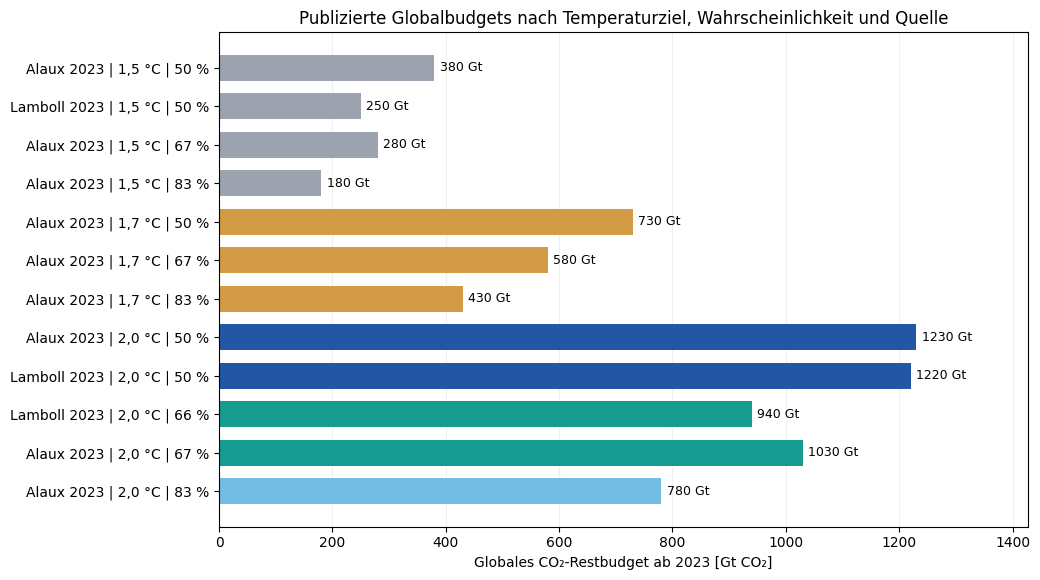

In [4]:
# Globale Ausgangsbudgets: Farbcode wie im späteren Gesamtdiagramm
from matplotlib.patches import Patch

def scenario_color(temperature, probability):
    t = float(str(temperature).replace(',', '.').split(' ')[0])
    p = float(probability)
    if t < 1.6: return '#9ca3af'          # 1,5 °C – historische, graue Szenarioklasse
    if t < 1.8: return '#d39b45'          # 1,7 °C
    if p <= 50: return '#2456a6'          # 2,0 °C, 50 %
    if p <= 67: return '#169b91'          # 2,0 °C, 66/67 %
    return '#74bde2'                     # 2,0 °C, 83 %

cols = ['quelle','temperatur','wahrscheinlichkeit_pct','referenzjahr','global_budget_Gt','quelle_id']
display(global_budgets[cols].sort_values(['temperatur','wahrscheinlichkeit_pct','quelle']))
df = global_budgets.copy().sort_values(['temperatur','wahrscheinlichkeit_pct','quelle'])
labels = [f'{r.quelle} | {r.temperatur} | {int(r.wahrscheinlichkeit_pct)} %' for r in df.itertuples()]
fig, ax = plt.subplots(figsize=(10.5, 5.9))
bars = ax.barh(labels, df.global_budget_Gt, height=.68,
               color=[scenario_color(r.temperatur, r.wahrscheinlichkeit_pct) for r in df.itertuples()])
ax.bar_label(bars, fmt='%.0f Gt', padding=4, fontsize=9)
ax.set_xlim(0, df.global_budget_Gt.max()*1.16)
ax.invert_yaxis(); ax.set_axisbelow(True)
ax.set(xlabel='Globales CO₂-Restbudget ab 2023 [Gt CO₂]', ylabel='',
       title='Publizierte Globalbudgets nach Temperaturziel, Wahrscheinlichkeit und Quelle')
ax.grid(axis='x', alpha=.2); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

,jahr,reihe,emissionen_Mt,einheit,quelle_id,datenstatus
0,2022,CO2_TERRITORIAL,NaN,Mt CO2,S7,offen; CO2-Jahreswert fehlt
1,2023,CO2_TERRITORIAL,NaN,Mt CO2,S7,offen; CO2-Jahreswert fehlt
2,2024,CO2_TERRITORIAL,NaN,Mt CO2,S7,offen; CO2-Jahreswert fehlt
3,2025,CO2_TERRITORIAL,NaN,Mt CO2,NaN,offen; für 2026-Budget notwendig
4,2022,GHG_TOTAL_EXCL_LULUCF,73.506582,Mt CO2e,S7,kontext: NICHT CO2-Budget-kompatibel
5,2023,GHG_TOTAL_EXCL_LULUCF,68.674060,Mt CO2e,S7,kontext: NICHT CO2-Budget-kompatibel
6,2024,GHG_TOTAL_EXCL_LULUCF,66.637831,Mt CO2e,S7,kontext: NICHT CO2-Budget-kompatibel
7,2025,GHG_TOTAL_EXCL_LULUCF,67.100000,Mt CO2e,S8,vorläufig; NICHT CO2-Budget-kompatibel


,von_jahr,bis_jahr,reihe,emissionen_Mt,einheit,quelle_id,herleitung,hinweis
0,2022,2024,CO2_TERRITORIAL,150.0,Mt CO2,S1-A1,"Schneider et al. 2025, Tab. A1: 280-130 bzw. 340-190",aggregierte historische Abzugsannahme; keine jährliche Inventarreihe


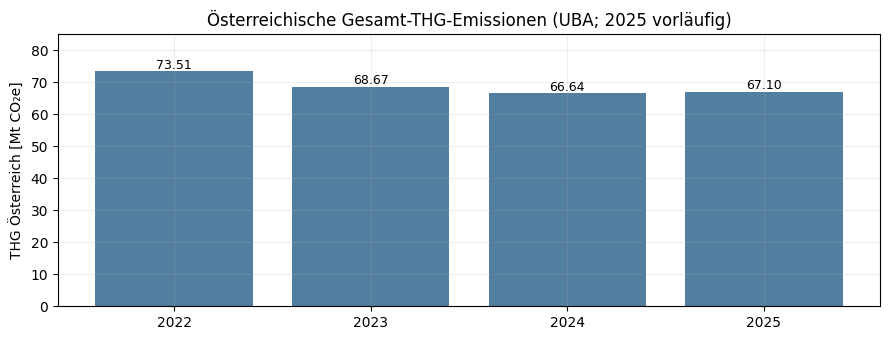

In [5]:
display(history[['jahr','reihe','emissionen_Mt','einheit','quelle_id','datenstatus']].sort_values(['reihe','jahr']).reset_index(drop=True))
display(aggregates)
fig,ax=plt.subplots(figsize=(9,3.5))
inv=history.loc[history.reihe=='GHG_TOTAL_EXCL_LULUCF'].sort_values('jahr')
ax.bar(inv.jahr.astype(int).astype(str), inv.emissionen_Mt, color='#527e9f')
for i,row in enumerate(inv.itertuples()):
    ax.text(i,row.emissionen_Mt+0.7,f'{row.emissionen_Mt:.2f}',ha='center',fontsize=9)
ax.set(ylabel='THG Österreich [Mt CO₂e]', title='Österreichische Gesamt-THG-Emissionen (UBA; 2025 vorläufig)')
ax.set_ylim(0,85)
plt.tight_layout();plt.show()

## 2. Stellschrauben

Die Werte in der folgenden Codezelle ändern und die nachfolgenden Zellen erneut ausführen.

In [6]:
# ===== BEWERTUNGSJAHR / BUDGET =====
EVALUATION_YEARS = [2025, 2026]  # verbleibende Budgets jeweils am 1. Januar
SELECTED_BUDGET_ID = 'LAMBOLL2023_AT_20_50'
SINK_LEVELS = {'L1': 0.0, 'L2': 0.5, 'L3': 1.0}  # t CO₂e/(Person a)
POPULATION_MILLION = 9.0
SECTOR_SHARE = 0.50  # Historische PEQ-Kalibrierung: Gebäude + MIV
# Expliziter Vergleich zweier sektoraler Allokationsannahmen (NICHT gleiche Systemgrenze)
SECTOR_SHARES = {'Alaux – FOA Buildings (37 %)': 0.37,
                 'PEQ – Gebäude + MIV (50 %)': 0.50}
COMPARISON_YEAR = 2026  # alle neuen Varianten im großen Abschlussdiagramm
COMPARISON_EPC_METHOD = 'EPC Alaux (0,10 %)'  # alternatives AT/Welt (2023) separat verfügbar
REFERENCE_GFA_MILLION_M2 = 906.7  # historische S1-Abgrenzung
ASSESSMENT_END_YEAR = 2075
HORIZON_POLICY = 'fixed_end'  # Alternativ: 'rolling_50'
REPRODUCTION_HISTORY = 'S1_aggregat'  # nur ursprüngliche Publikation
MODERN_HISTORY = 'GHG_TOTAL_EXCL_LULUCF'  # UBA-THG als CO₂e-Näherung
ALLOW_GHG_AS_CO2_PROXY = True

# ===== GLOBALES BUDGET UND AT-ALLOKATION =====
EPC_AT_POPULATION_SHARE = 0.001  # 0,10 %, Alaux et al. (2023), 2023–2050; dort für FOA buildings
# Vergleichsquote 2023: AT / Welt, World Bank, Indikator SP.POP.TOTL.
# Unabhängig von POPULATION_MILLION (9 Mio.; historische Senkenannahme).
AT_POPULATION_2023 = 9_131_761   # Personen; World Bank 2023, AT (S10)
WORLD_POPULATION_2023 = 8_062_923_417  # Personen; World Bank 2023, Welt (S11)
EPC_AT_SHARE_2023 = AT_POPULATION_2023 / WORLD_POPULATION_2023
EPC_METHODS = {
    'EPC Alaux (0,10 %)': EPC_AT_POPULATION_SHARE,
    'AT/Welt (2023)': EPC_AT_SHARE_2023,
}
SINK_COMPARISON = {'ohne Senken': 0.0, 'mit Senken': 1.0}  # t CO₂e/(Person a)

LAMBOLL_20_50_REPORTED_ROUNDED_Gt = 1200.0  # Lamboll (2023), ca. 1.200 Gt im Abstract
assert HORIZON_POLICY in ('fixed_end', 'rolling_50')
assert all(isinstance(y,int) for y in EVALUATION_YEARS)
assert 0 <= SECTOR_SHARE <= 1 and REFERENCE_GFA_MILLION_M2 > 0
assert POPULATION_MILLION > 0 and 0 < EPC_AT_POPULATION_SHARE < 1

# Globalbudgets aus quellenspezifischer CSV (Referenzjahr 2023, 2 °C, 50 %).
def global_budget_value(source_name, temp='2,0 °C', probability=50, ref_year=2023):
    matching = global_budgets.loc[
        (global_budgets.quelle == source_name) &
        (global_budgets.temperatur == temp) &
        (global_budgets.wahrscheinlichkeit_pct == probability) &
        (global_budgets.referenzjahr == ref_year)]
    if len(matching) != 1: raise ValueError(f'Globales Budget nicht eindeutig: {source_name}, {temp}, {probability} %, {ref_year}')
    if matching.iloc[0].einheit != 'Gt CO2': raise ValueError('Unerwartete globale Budgeteinheit')
    return float(matching.iloc[0].global_budget_Gt)

lamboll_exact_Gt = global_budget_value('Lamboll 2023')
alaux_exact_Gt = global_budget_value('Alaux 2023')
assert abs(lamboll_exact_Gt - LAMBOLL_20_50_REPORTED_ROUNDED_Gt) < 50, 'Gerundeter und präziser Lamboll-Betrag unvereinbar'

# Umrechnung Gt → Mt und EPC-Verteilung. Der gerundete Wert wird für die Hauptrechnung verwendet.
epc_allocated_budget_Mt = LAMBOLL_20_50_REPORTED_ROUNDED_Gt * 1000 * EPC_AT_POPULATION_SHARE
budget_mask = budgets.budget_id.eq(SELECTED_BUDGET_ID)
assert budget_mask.sum() == 1
# Die nationale Zahl wird berechnet, NICHT als zweiter, unsichtbarer Input aus einer CSV übernommen.
# Falls in der Eingangstabelle bereits eine Zahl eingetragen wurde, Konflikt melden.
previous = budgets.loc[budget_mask,'national_budget_Mt'].iloc[0]
if pd.notna(previous) and not math.isclose(float(previous), epc_allocated_budget_Mt):
    raise ValueError(f'Widersprüchlicher nationaler CSV-Wert: {previous} != EPC {epc_allocated_budget_Mt}')
budgets.loc[budget_mask,'national_budget_Mt'] = epc_allocated_budget_Mt
budgets.loc[budget_mask,'quelle_id'] = 'S6+S9'
budgets.loc[budget_mask,'datenstatus'] = 'Abgeleitet: gerundetes Lamboll-Globalbudget × 0,10 % EPC (Alaux); Modellübertragung'
# Auch für die weiteren belegten Lamboll-Szenarien verfügbare AT-Budgets
# errechnen. Fehlt die globale Ausgangszahl (z. B. 1,5 °C / 66 %), bleibt
# die nationale Zeile ausdrücklich ohne Zahl.
for budget_id, temp, likelihood in [
    ('LAMBOLL2023_AT_15_50', '1,5 °C', 50),
    ('LAMBOLL2023_AT_20_66', '2,0 °C', 66),
]:
    m = budgets.budget_id.eq(budget_id)
    assert m.sum() == 1
    derived = global_budget_value('Lamboll 2023', temp, likelihood) * 1000 * EPC_AT_POPULATION_SHARE
    old = budgets.loc[m, 'national_budget_Mt'].iloc[0]
    if pd.notna(old) and not math.isclose(float(old), derived):
        raise ValueError(f'Abweichende CSV-Angabe für {budget_id}: {old} statt {derived}')
    budgets.loc[m, 'national_budget_Mt'] = derived
    budgets.loc[m, 'quelle_id'] = 'S6+S9'
    budgets.loc[m, 'datenstatus'] = 'Aus Lamboll global × 0,10 % EPC (Alaux) abgeleitet'


allocation_comparison = pd.DataFrame([
    {'Globalquelle':'Lamboll 2023 (gerundet, HAUPTLAUF)', 'Globalbudget [Gt CO₂]':LAMBOLL_20_50_REPORTED_ROUNDED_Gt, 'EPC-Anteil [%]':100*EPC_AT_POPULATION_SHARE,'AT-Budget [Mt CO₂]':epc_allocated_budget_Mt,'Quelle':'S6 (Abstract) + S9 (EPC)'},
    {'Globalquelle':'Lamboll 2023 (detaillierter Artikelwert)', 'Globalbudget [Gt CO₂]':lamboll_exact_Gt, 'EPC-Anteil [%]':100*EPC_AT_POPULATION_SHARE,'AT-Budget [Mt CO₂]':lamboll_exact_Gt*1000*EPC_AT_POPULATION_SHARE,'Quelle':'S6 (Artikel) + S9 (EPC)'},
    {'Globalquelle':'Alaux 2023 (andere globale Budgetquelle)', 'Globalbudget [Gt CO₂]':alaux_exact_Gt,'EPC-Anteil [%]':100*EPC_AT_POPULATION_SHARE,'AT-Budget [Mt CO₂]':alaux_exact_Gt*1000*EPC_AT_POPULATION_SHARE,'Quelle':'S9 (Tab. 1 und EPC)'}
])
print('Globales Budget → Österreichisches Budget (EPC):')
display(allocation_comparison)
print(f'Lamboll gerundet {LAMBOLL_20_50_REPORTED_ROUNDED_Gt:.0f} Gt × EPC {100*EPC_AT_POPULATION_SHARE:.3f} % = {epc_allocated_budget_Mt:.1f} Mt CO₂ (AT ab 2023)')
assert COMPARISON_EPC_METHOD in EPC_METHODS
assert COMPARISON_YEAR in EVALUATION_YEARS


Globales Budget → Österreichisches Budget (EPC):


,Globalquelle,Globalbudget [Gt CO₂],EPC-Anteil [%],AT-Budget [Mt CO₂],Quelle
0,"Lamboll 2023 (gerundet, HAUPTLAUF)",1200.0,0.1,1200.0,S6 (Abstract) + S9 (EPC)
1,Lamboll 2023 (detaillierter Artikelwert),1220.0,0.1,1220.0,S6 (Artikel) + S9 (EPC)
2,Alaux 2023 (andere globale Budgetquelle),1230.0,0.1,1230.0,S9 (Tab. 1 und EPC)


Lamboll gerundet 1200 Gt × EPC 0.100 % = 1200.0 Mt CO₂ (AT ab 2023)


## 3. Rechenmodell

$$
B_{\mathrm{AT},r}=1000\,B_{\mathrm{global},r}\,f_{\mathrm{EPC}}
$$

$$
B_{\mathrm{AT},t}=B_{\mathrm{AT},r}-\sum_{y=r}^{t-1}E_{\mathrm{AT},y}
$$

$$
B_{\mathrm{Sektor},t}(s,\alpha)=\alpha\left(B_{\mathrm{AT},t}+P\,s\,(2075-t)\right)
$$

$$
\boxed{b_{\mathrm{THG},t}(s,\alpha)=\frac{1000\,B_{\mathrm{Sektor},t}(s,\alpha)}{A_{\mathrm{BGF}}}}
$$

*Einheiten:* global Gt CO₂, national und Sektor Mt, Bevölkerung Mio., Senken t CO₂e/(Person·a), Fläche Mio. m² BGF, Ergebnis kg CO₂e/m² BGF.

::: {.callout-important title="Sektorgrenzen"}
**37 % (Alaux):** *Field of Action Buildings* als globale Budgetallokation für Lebenszyklusemissionen des Gebäudebestands. **50 % (PEQ):** bisherige Budgetallokation auf **Gebäude + MIV**. Die Gegenüberstellung ist eine **Sensitivitäts- und Systemgrenzenanalyse**; die 37-%-Spalte ist kein publizierter PEQ-Grenzwert.
:::

::: {.callout-warning title="Vorläufige Abzugs- und Senkenannahmen" collapse="true"}
Die jährlichen UBA-Werte sind **gesamte THG in CO₂e ohne LULUCF**. Ihr Abzug von CO₂-only-Budgets ist eine vorläufige Näherung. Zusätzliche natürliche Senken werden hier als eigene Modellannahme von 0 oder 1 t CO₂e je Person und Jahr angesetzt; Doppelzählung gegenüber globalen Budgetannahmen ist vor einer normativen Festlegung zu prüfen.
:::


In [7]:
@dataclass(frozen=True)
class AllocationInputs:
    remaining_budget_Mt: float
    population_M: float
    sinks_t_per_cap_a: float
    years_remaining: int
    sector_share: float
    gfa_Mm2: float

def allocate_ghg_budget(x: AllocationInputs) -> dict:
    vals=asdict(x)
    if not all(math.isfinite(float(v)) for v in vals.values()):
        raise ValueError('Nicht numerisch belegte Parameter.')
    if x.population_M <= 0 or x.years_remaining < 0 or x.gfa_Mm2 <= 0:
        raise ValueError('Bevölkerung, Restlaufzeit oder BGF ungültig.')
    if x.sinks_t_per_cap_a < 0 or not 0 <= x.sector_share <= 1:
        raise ValueError('Senken/Sektoranteil ungültig.')
    sinks_Mt=x.population_M*x.sinks_t_per_cap_a*x.years_remaining
    national=x.remaining_budget_Mt+sinks_Mt
    sector=x.sector_share*national
    return {'remaining_CO2_budget_Mt': x.remaining_budget_Mt,
            'additional_sinks_Mt': sinks_Mt, 'national_with_sinks_Mt': national,
            'sector_budget_Mt':sector, 'target_kgCO2e_m2_BGF': 1000*sector/x.gfa_Mm2}

class HistoricalDataGap(ValueError):
    pass

def budget_row(budget_id):
    subset=budgets.loc[budgets.budget_id==budget_id]
    if len(subset)!=1: raise ValueError('Budget-ID nicht eindeutig: '+budget_id)
    return subset.iloc[0]

def years_remaining(eval_year):
    return max(0, ASSESSMENT_END_YEAR-int(eval_year)) if HORIZON_POLICY=='fixed_end' else 50

def historical_deduction(start_year:int, eval_year:int, mode='CO2_TERRITORIAL'):
    """Emissionsabzug für [start_year, eval_year); keine Schätzungen für Lücken."""
    if eval_year < start_year: raise ValueError('Bewertungsjahr vor Referenzjahr')
    if eval_year == start_year: return 0.0, []
    pending=set(range(start_year,eval_year)); items=[]
    if mode=='S1_aggregat':
        # Ein einziger, zeitlich geschlossener Block für 2022-2024 (keine erfundenen Jahreswerte).
        matching=aggregates.loc[(aggregates.reihe=='CO2_TERRITORIAL') &
            (aggregates.von_jahr==2022) & (aggregates.bis_jahr==2024)]
        if start_year<=2022 and eval_year>=2025 and len(matching)==1:
            entry=matching.iloc[0]
            if pd.notna(entry.emissionen_Mt):
                items.append({'jahre':'2022–2024', 'Mt':float(entry.emissionen_Mt), 'quelle':entry.quelle_id})
                pending.difference_update(range(2022,2025))
    if mode not in ('S1_aggregat','CO2_TERRITORIAL','GHG_TOTAL_EXCL_LULUCF'):
        raise ValueError(f'Unbekannte historische Reihe: {mode}')
    if mode=='GHG_TOTAL_EXCL_LULUCF' and not ALLOW_GHG_AS_CO2_PROXY:
        raise ValueError('GHG/CO₂-Näherung durch ALLOW_GHG_AS_CO2_PROXY=False gesperrt.')
    reihe='CO2_TERRITORIAL' if mode=='S1_aggregat' else mode
    expected='Mt CO2e' if reihe=='GHG_TOTAL_EXCL_LULUCF' else 'Mt CO2'
    for yr in sorted(pending):
        subset=history.loc[(history.jahr==yr)&(history.reihe==reihe)]
        if len(subset)!=1 or pd.isna(subset.iloc[0].emissionen_Mt):
            raise HistoricalDataGap(f'Jahresemissionen fehlen: Jahr {yr} (Zeile {reihe}).')
        entry=subset.iloc[0]
        if entry.einheit != expected:
            raise ValueError(f'Einheitenkonflikt: {yr} = {entry.einheit}, erwartet {expected}')
        items.append({'jahre':str(yr), 'Mt':float(entry.emissionen_Mt),
                      'einheit':expected, 'quelle':entry.quelle_id,
                      'datenstatus':entry.datenstatus})
    return sum(item['Mt'] for item in items),items

def calculate_scenario(budget_id, eval_year, sink=1.0, history_mode='CO2_TERRITORIAL'):
    b=budget_row(budget_id)
    r=int(b.referenzjahr)
    if pd.isna(b.national_budget_Mt):
        raise HistoricalDataGap(f'Nationales AT-Budget fehlt für {budget_id}.')
    if b.einheit!='Mt CO2': raise ValueError('Budget benötigt Mt CO2, nicht globales Gt- oder THG-CO2e-Budget.')
    subtraction,parts=historical_deduction(r,int(eval_year),history_mode)
    remaining=float(b.national_budget_Mt)-subtraction  # kein implizites Abschneiden bei 0
    result=allocate_ghg_budget(AllocationInputs(remaining,POPULATION_MILLION,sink,
                              years_remaining(eval_year), SECTOR_SHARE, REFERENCE_GFA_MILLION_M2))
    return {'budget_id':budget_id,'quelle':b.quelle_id,'referenzjahr':r,'bewertungsjahr':int(eval_year),
            'start_budget_Mt':float(b.national_budget_Mt),'historical_deduction_Mt':subtraction,
            'abzug_komponenten':parts,'senken_t_cap_a':sink,'jahre_senken':years_remaining(eval_year),
            **result,
            'historische_reihe': history_mode,
            'abzug_ist_CO2e_Naeherung': history_mode=='GHG_TOTAL_EXCL_LULUCF',
            'hinweis': ('ACHTUNG: Gesamt-THG in Mt CO2e von CO2-only-Budget abgezogen (Näherung); '
                        + ('Ausgangsbudget überschritten' if remaining<0 else 'EPC-Allokation als Modellübertragung (S6+S9), nicht als nationale Publikationszahl')
                        if history_mode=='GHG_TOTAL_EXCL_LULUCF'
                        else ('erschöpftes CO2-Budget' if remaining<0 else 'rechenbar'))}

## 4. Historische Steininger-/Schneider-Kalibrierung (2025)

L1–L3: 1,5 °C / 66 % / ohne Overshoot; Senkenannahme L1 = 0, L2 = 0,5, L3 = 1 t CO₂e/(Person·a).

,budget_id,referenzjahr,bewertungsjahr,start_budget_Mt,historical_deduction_Mt,remaining_CO2_budget_Mt,level,senken_t_cap_a,additional_sinks_Mt,sector_budget_Mt,target_kgCO2e_m2_BGF
0,STEIN2022_15_NO_66,2022,2025,280.0,150.0,130.0,L1,0.0,0.0,65.0,71.688541
1,STEIN2022_15_NO_66,2022,2025,280.0,150.0,130.0,L2,0.5,225.0,177.5,195.764862
2,STEIN2022_15_NO_66,2022,2025,280.0,150.0,130.0,L3,1.0,450.0,290.0,319.841182
3,STEIN2022_15_YES_66,2022,2025,340.0,150.0,190.0,L1,0.0,0.0,95.0,104.775560
4,STEIN2022_15_YES_66,2022,2025,340.0,150.0,190.0,L2,0.5,225.0,207.5,228.851880
5,STEIN2022_15_YES_66,2022,2025,340.0,150.0,190.0,L3,1.0,450.0,320.0,352.928201


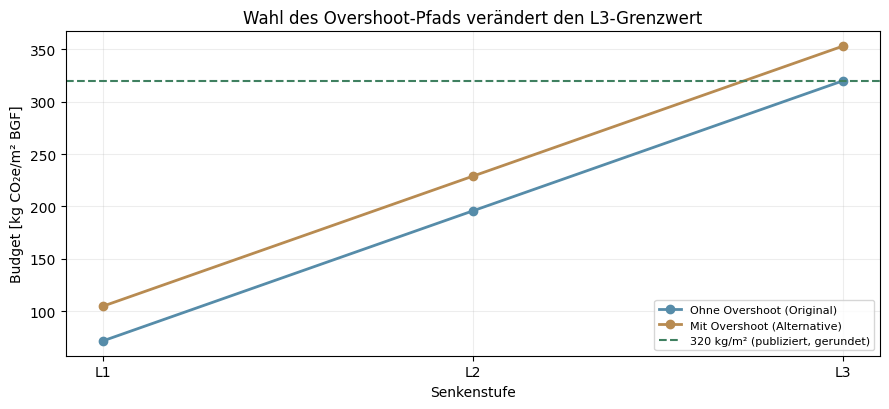

In [8]:
reference_id = 'STEIN2022_15_NO_66'
overshoot_id = 'STEIN2022_15_YES_66'
reference_cases = []
for budget_id in (reference_id, overshoot_id):
    for label,sink in SINK_LEVELS.items():
        res=calculate_scenario(budget_id,2025,sink,history_mode=REPRODUCTION_HISTORY)
        reference_cases.append({k:v for k,v in res.items() if k!='abzug_komponenten'}|{'level':label})
ref_table=pd.DataFrame(reference_cases)
display(ref_table[['budget_id','referenzjahr','bewertungsjahr','start_budget_Mt',
    'historical_deduction_Mt','remaining_CO2_budget_Mt','level','senken_t_cap_a',
    'additional_sinks_Mt','sector_budget_Mt','target_kgCO2e_m2_BGF']])
fig,ax=plt.subplots(figsize=(9,4.2))
for name,part,color in [('Ohne Overshoot (Original)',reference_id,'#568ca9'),
                         ('Mit Overshoot (Alternative)',overshoot_id,'#b88b51')]:
    sub=ref_table.loc[ref_table.budget_id==part].set_index('level').reindex(['L1','L2','L3'])
    ax.plot(sub.index,sub.target_kgCO2e_m2_BGF,marker='o',lw=2,label=name,color=color)
ax.axhline(320,color='#3f8060',ls='--',label='320 kg/m² (publiziert, gerundet)')
ax.set(xlabel='Senkenstufe',ylabel='Budget [kg CO₂e/m² BGF]',title='Wahl des Overshoot-Pfads verändert den L3-Grenzwert')
ax.legend(fontsize=8);plt.tight_layout();plt.show()

## 5. Lamboll × EPC – Bewertung 2025 / 2026

In [9]:
COMPARE_BUDGET_IDS = [reference_id, overshoot_id, SELECTED_BUDGET_ID]
future_rows=[]
for bid in dict.fromkeys(COMPARE_BUDGET_IDS):
    for year in EVALUATION_YEARS:
        mode=REPRODUCTION_HISTORY if bid.startswith('STEIN') else MODERN_HISTORY
        try:
            rec=calculate_scenario(bid,year,SINK_LEVELS['L3'],mode)
            future_rows.append({'budget_id':bid,'bewertungsjahr':year,'referenzjahr':rec['referenzjahr'],
              'historischer_abzug_Mt':rec['historical_deduction_Mt'],
              'restbudget_Mt':rec['remaining_CO2_budget_Mt'],
              'L3_kgCO2e_m2_BGF':rec['target_kgCO2e_m2_BGF'],
              'senkenjahre':rec['jahre_senken'],'abzug_reihe':rec['historische_reihe'], 'status':rec['hinweis']})
        except (HistoricalDataGap,ValueError) as err:
            future_rows.append({'budget_id':bid,'bewertungsjahr':year,
               'referenzjahr':int(budget_row(bid).referenzjahr),
               'historischer_abzug_Mt':np.nan,'restbudget_Mt':np.nan,
               'L3_kgCO2e_m2_BGF':np.nan,'senkenjahre':years_remaining(year),
               'abzug_reihe':mode, 'status':str(err)})
comparison_years=pd.DataFrame(future_rows)
display(comparison_years)

,budget_id,bewertungsjahr,referenzjahr,historischer_abzug_Mt,restbudget_Mt,L3_kgCO2e_m2_BGF,senkenjahre,abzug_reihe,status
0,STEIN2022_15_NO_66,2025,2022,150.000000,130.000000,319.841182,50,S1_aggregat,rechenbar
1,STEIN2022_15_NO_66,2026,2022,NaN,NaN,NaN,49,S1_aggregat,Jahresemissionen fehlen: Jahr 2025 (Zeile CO2_TERRITORIAL).
2,STEIN2022_15_YES_66,2025,2022,150.000000,190.000000,352.928201,50,S1_aggregat,rechenbar
3,STEIN2022_15_YES_66,2026,2022,NaN,NaN,NaN,49,S1_aggregat,Jahresemissionen fehlen: Jahr 2025 (Zeile CO2_TERRITORIAL).
4,LAMBOLL2023_AT_20_50,2025,2023,135.311891,1064.688109,835.275234,50,GHG_TOTAL_EXCL_LULUCF,ACHTUNG: Gesamt-THG in Mt CO2e von CO2-only-Budget abgezogen (Näherung); EPC-Allokation als Modellübe...
5,LAMBOLL2023_AT_20_50,2026,2023,202.411891,997.588109,793.309865,49,GHG_TOTAL_EXCL_LULUCF,ACHTUNG: Gesamt-THG in Mt CO2e von CO2-only-Budget abgezogen (Näherung); EPC-Allokation als Modellübe...


,budget_id,schritt,wert_Mt,quelle
0,STEIN2022_15_NO_66,1 Ausgangsbudget ab Referenzjahr,280.0,S1-A1
1,STEIN2022_15_NO_66,2 Historisch emittiert,-150.0,S1-A1
2,STEIN2022_15_NO_66,3 Verbleibendes Budget,130.0,Berechnung
3,STEIN2022_15_NO_66,4 Zusätzliche Senken,450.0,S1-A1 / Annahme
4,STEIN2022_15_NO_66,5 National mit Senken,580.0,Berechnung
5,STEIN2022_15_NO_66,6 Sektorbudget (50 %),290.0,Berechnung
6,STEIN2022_15_YES_66,1 Ausgangsbudget ab Referenzjahr,340.0,S1-A1
7,STEIN2022_15_YES_66,2 Historisch emittiert,-150.0,S1-A1
8,STEIN2022_15_YES_66,3 Verbleibendes Budget,190.0,Berechnung
9,STEIN2022_15_YES_66,4 Zusätzliche Senken,450.0,S1-A1 / Annahme


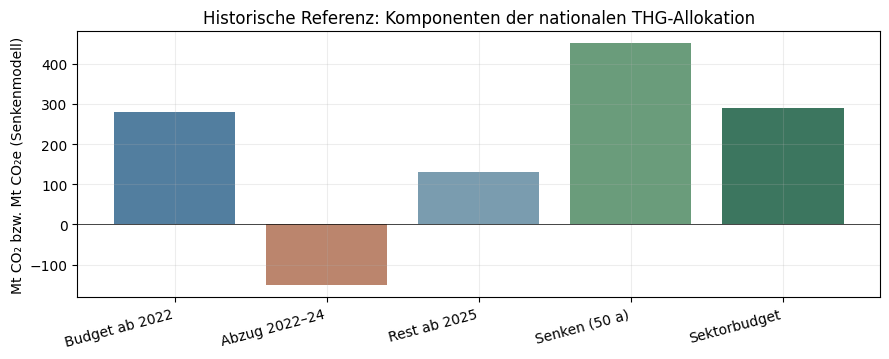

Lamboll 2023 (gerundetes Globalbudget) × EPC nach Alaux (AT-Ausgangsbudget 1.200 Mt): UBA-Abzug als CO₂e-Näherung


,Referenzjahr,Ausgangsbudget [Mt CO₂],historischer UBA-THG-Abzug [Mt CO₂e],Restbudget [Mt] (Näherung),Senken [Mt],Gebäude + MIV [Mt],L3 [kg CO₂e/m² BGF],Abzugsjahre,Quellen
Bewertungsjahr,,,,,,,,,
2025,2023,1200.0,135.312,1064.688,450.0,757.344,835.275,"2023, 2024","S7, S7"
2026,2023,1200.0,202.412,997.588,441.0,719.294,793.310,"2023, 2024, 2025","S7, S7, S8"


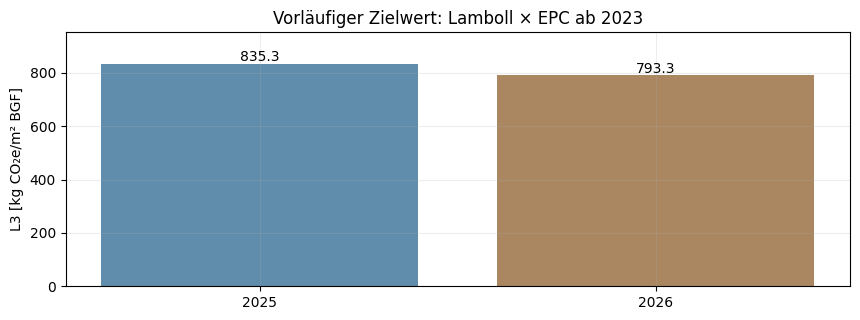

In [10]:
steps=[]
for bid in (reference_id,overshoot_id):
    rec=calculate_scenario(bid,2025,1.0,REPRODUCTION_HISTORY)
    steps += [dict(budget_id=bid,schritt='1 Ausgangsbudget ab Referenzjahr',wert_Mt=rec['start_budget_Mt'],quelle=rec['quelle']),
              dict(budget_id=bid,schritt='2 Historisch emittiert',wert_Mt=-rec['historical_deduction_Mt'],quelle='S1-A1'),
              dict(budget_id=bid,schritt='3 Verbleibendes Budget',wert_Mt=rec['remaining_CO2_budget_Mt'],quelle='Berechnung'),
              dict(budget_id=bid,schritt='4 Zusätzliche Senken',wert_Mt=rec['additional_sinks_Mt'],quelle='S1-A1 / Annahme'),
              dict(budget_id=bid,schritt='5 National mit Senken',wert_Mt=rec['national_with_sinks_Mt'],quelle='Berechnung'),
              dict(budget_id=bid,schritt='6 Sektorbudget (50 %)',wert_Mt=rec['sector_budget_Mt'],quelle='Berechnung')]
steps_table=pd.DataFrame(steps)
display(steps_table)
rec=calculate_scenario(reference_id,2025,1.0,REPRODUCTION_HISTORY)
fig, ax = plt.subplots(figsize=(9,3.7))
labels=['Budget ab 2022','Abzug 2022–24','Rest ab 2025','Senken (50 a)','Sektorbudget']
values=[rec['start_budget_Mt'],-rec['historical_deduction_Mt'],rec['remaining_CO2_budget_Mt'],
        rec['additional_sinks_Mt'],rec['sector_budget_Mt']]
ax.bar(labels,values,color=['#527e9f','#bb856d','#7a9caf','#6a9c7b','#3c765f'])
ax.axhline(0,color='black',lw=.5)
ax.set(ylabel='Mt CO₂ bzw. Mt CO₂e (Senkenmodell)',title='Historische Referenz: Komponenten der nationalen THG-Allokation')
plt.xticks(rotation=15,ha='right');plt.tight_layout();plt.show()

# Zusätzliche, unveränderte Allokationslogik für das Arbeitsbudget ab 2023
working=[]
for y in EVALUATION_YEARS:
    w=calculate_scenario(SELECTED_BUDGET_ID,y,1.0,MODERN_HISTORY)
    working.append({'Bewertungsjahr':y, 'Referenzjahr':w['referenzjahr'],
                    'Ausgangsbudget [Mt CO₂]':w['start_budget_Mt'],
                    'historischer UBA-THG-Abzug [Mt CO₂e]':w['historical_deduction_Mt'],
                    'Restbudget [Mt] (Näherung)':w['remaining_CO2_budget_Mt'],
                    'Senken [Mt]':w['additional_sinks_Mt'],
                    'Gebäude + MIV [Mt]':w['sector_budget_Mt'],
                    'L3 [kg CO₂e/m² BGF]':w['target_kgCO2e_m2_BGF'],
                    'Abzugsjahre':', '.join(x['jahre'] for x in w['abzug_komponenten']),
                    'Quellen':', '.join(x['quelle'] for x in w['abzug_komponenten'])})
working_table=pd.DataFrame(working).set_index('Bewertungsjahr')
print('Lamboll 2023 (gerundetes Globalbudget) × EPC nach Alaux (AT-Ausgangsbudget 1.200 Mt): UBA-Abzug als CO₂e-Näherung')
display(working_table.round(3))
fig, ax = plt.subplots(figsize=(8.7,3.3))
cols=['2025','2026']; vals=working_table['L3 [kg CO₂e/m² BGF]'].to_numpy()
bar=ax.bar(cols, vals, color=['#608dab','#aa8661'])
for b,v in zip(bar,vals):ax.text(b.get_x()+b.get_width()/2,v+8,f'{v:.1f}',ha='center')
ax.set(ylabel='L3 [kg CO₂e/m² BGF]',title='Vorläufiger Zielwert: Lamboll × EPC ab 2023')
ax.set_ylim(0,max(vals)*1.14)
plt.tight_layout();plt.show()


## 6. Globale Budgets × EPC – bisheriger Senkenvergleich

EPC Alaux (0,10 %) und AT/Welt (2023), jeweils ohne und mit Senken; die gemeinsame sektorale Auswertung folgt weiter unten.

In [11]:
# Bevölkerungsbasierte nationale Budgetanteile (getrennt von der Senkenbevölkerung)
bevoelkerungsvergleich = pd.DataFrame([
    {'Allokation': 'Alaux EPC (2023–2050, gerundet)', 'AT-Bevölkerung 2023': np.nan,
     'Weltbevölkerung 2023': np.nan, 'AT-Anteil [%]': EPC_AT_POPULATION_SHARE*100,
     'Quelle': 'S9; übertragener EPC-Faktor'},
    {'Allokation': 'World Bank 2023 (Jahresquote)', 'AT-Bevölkerung 2023': AT_POPULATION_2023,
     'Weltbevölkerung 2023': WORLD_POPULATION_2023, 'AT-Anteil [%]': EPC_AT_SHARE_2023*100,
     'Quelle': 'S10 / S11; AT/Welt, 2023'},
])
print('Alternative Allokationsfaktoren – kein zusätzliches Bevölkerungsmodell:')
display(bevoelkerungsvergleich)
assert 0 < EPC_AT_SHARE_2023 < .01
assert math.isclose(EPC_AT_SHARE_2023, AT_POPULATION_2023/WORLD_POPULATION_2023)


Alternative Allokationsfaktoren – kein zusätzliches Bevölkerungsmodell:


,Allokation,AT-Bevölkerung 2023,Weltbevölkerung 2023,AT-Anteil [%],Quelle
0,"Alaux EPC (2023–2050, gerundet)",NaN,NaN,0.100000,S9; übertragener EPC-Faktor
1,World Bank 2023 (Jahresquote),9131761.0,8.062923e+09,0.113256,"S10 / S11; AT/Welt, 2023"


In [12]:
# Alle belegten globalen Budgetvarianten, einschließlich gerundeter Lamboll-Arbeitsbasis.
# Das Zielbudget wird stets zuerst aus global [Gt] × 1000 × Bevölkerungsanteil
# berechnet; anschließend folgen historischer Abzug, Senken und Flächenallokation.
global_faelle = global_budgets[['quelle', 'temperatur', 'wahrscheinlichkeit_pct',
                               'referenzjahr', 'global_budget_Gt', 'quelle_id']].copy()
global_faelle['Szenario'] = global_faelle.apply(
    lambda r: f"{r['quelle']} | {r['temperatur']} | {int(r['wahrscheinlichkeit_pct'])} %", axis=1)
# Ergänzter Rechenfall mit genau dem bisherigen gerundeten 1.200-Gt-Budget.
rounded_case = pd.DataFrame([{
    'quelle': 'Lamboll 2023 (gerundet)', 'temperatur': '2,0 °C',
    'wahrscheinlichkeit_pct': 50, 'referenzjahr': 2023,
    'global_budget_Gt': LAMBOLL_20_50_REPORTED_ROUNDED_Gt,
    'quelle_id': 'S6', 'Szenario': 'Lamboll gerundet | 2,0 °C | 50 %',
}])
global_faelle = pd.concat([rounded_case, global_faelle], ignore_index=True)
assert global_faelle[['Szenario','referenzjahr']].duplicated().sum() == 0

neue_kalibrierung = []
for b in global_faelle.itertuples(index=False):
    for method, epc in EPC_METHODS.items():
        startbudget = b.global_budget_Gt * 1000 * epc
        for year in EVALUATION_YEARS:
            deduction, parts = historical_deduction(int(b.referenzjahr), year, MODERN_HISTORY)
            rest = startbudget - deduction  # negative Restbudgets sichtbar lassen
            result_without = allocate_ghg_budget(AllocationInputs(
                rest, POPULATION_MILLION, SINK_COMPARISON['ohne Senken'],
                years_remaining(year), SECTOR_SHARE, REFERENCE_GFA_MILLION_M2))
            result_with = allocate_ghg_budget(AllocationInputs(
                rest, POPULATION_MILLION, SINK_COMPARISON['mit Senken'],
                years_remaining(year), SECTOR_SHARE, REFERENCE_GFA_MILLION_M2))
            neue_kalibrierung.append({
                'Szenario': b.Szenario, 'Quelle': b.quelle, 'Temperatur': b.temperatur,
                'p [%]': int(b.wahrscheinlichkeit_pct), 'Referenzjahr': int(b.referenzjahr),
                'Global [Gt CO₂]': b.global_budget_Gt, 'Allokation': method,
                'AT-Anteil [%]': epc * 100, 'AT-Budget [Mt CO₂]': startbudget,
                'Bewertungsjahr': year, 'UBA-Abzug [Mt CO₂e]': deduction,
                'Rest [Mt]': rest, 'Senkenjahre': years_remaining(year),
                'Zus. Senken [Mt]': result_with['additional_sinks_Mt'],
                'Ziel ohne Senken [kg/m²]': result_without['target_kgCO2e_m2_BGF'],
                'Ziel mit Senken [kg/m²]': result_with['target_kgCO2e_m2_BGF'],
                'Differenz Senken [kg/m²]': result_with['target_kgCO2e_m2_BGF'] - result_without['target_kgCO2e_m2_BGF'],
                'Quelle Budget': b.quelle_id, 'Abzug-Reihe': MODERN_HISTORY,
            })
neue_kalibrierung = pd.DataFrame(neue_kalibrierung)

print('Alle Klimabudgets – AT-Allokation und Senkenvergleich zum 1.1.2026:')
show_2026 = neue_kalibrierung.loc[neue_kalibrierung.Bewertungsjahr == 2026, [
    'Szenario', 'Global [Gt CO₂]', 'Allokation', 'AT-Anteil [%]',
    'AT-Budget [Mt CO₂]', 'UBA-Abzug [Mt CO₂e]', 'Rest [Mt]',
    'Ziel ohne Senken [kg/m²]', 'Ziel mit Senken [kg/m²]',
    'Differenz Senken [kg/m²]']]
display(show_2026.round(2))

print('Lamboll-Budgetvarianten – beide Jahre und beide Bevölkerungsquoten:')
lamboll_both_years = neue_kalibrierung.loc[
    neue_kalibrierung['Quelle'].isin(['Lamboll 2023', 'Lamboll 2023 (gerundet)']),
    ['Szenario', 'Bewertungsjahr', 'Allokation', 'AT-Budget [Mt CO₂]',
     'Rest [Mt]', 'Ziel ohne Senken [kg/m²]', 'Ziel mit Senken [kg/m²]']]
display(lamboll_both_years.round(1).reset_index(drop=True))

print('Hauptfall 1.200 Gt – alle vier Kombinationen aus Jahr und Allokationsfaktor:')
hauptfaelle = neue_kalibrierung.loc[
    neue_kalibrierung.Szenario == 'Lamboll gerundet | 2,0 °C | 50 %',
    ['Bewertungsjahr','Allokation','AT-Anteil [%]', 'AT-Budget [Mt CO₂]',
     'UBA-Abzug [Mt CO₂e]', 'Rest [Mt]', 'Senkenjahre', 'Zus. Senken [Mt]',
     'Ziel ohne Senken [kg/m²]', 'Ziel mit Senken [kg/m²]', 'Differenz Senken [kg/m²]']]
display(hauptfaelle.round(2).reset_index(drop=True))
print('Hinweis: UBA-Gesamt-THG (CO₂e) als Abzug von CO₂-only-Budget = vorläufige Näherung; '
      'Senken sind eine zusätzliche Modellannahme, kein beobachteter jährlicher Netto-Entzug.')


Alle Klimabudgets – AT-Allokation und Senkenvergleich zum 1.1.2026:


,Szenario,Global [Gt CO₂],Allokation,AT-Anteil [%],AT-Budget [Mt CO₂],UBA-Abzug [Mt CO₂e],Rest [Mt],Ziel ohne Senken [kg/m²],Ziel mit Senken [kg/m²],Differenz Senken [kg/m²]
1,"Lamboll gerundet | 2,0 °C | 50 %",1200.0,"EPC Alaux (0,10 %)",0.10,1200.00,202.41,997.59,550.12,793.31,243.19
3,"Lamboll gerundet | 2,0 °C | 50 %",1200.0,AT/Welt (2023),0.11,1359.07,202.41,1156.66,637.84,881.03,243.19
5,"Lamboll 2023 | 1,5 °C | 50 %",250.0,"EPC Alaux (0,10 %)",0.10,250.00,202.41,47.59,26.24,269.43,243.19
7,"Lamboll 2023 | 1,5 °C | 50 %",250.0,AT/Welt (2023),0.11,283.14,202.41,80.73,44.52,287.71,243.19
9,"Lamboll 2023 | 2,0 °C | 50 %",1220.0,"EPC Alaux (0,10 %)",0.10,1220.00,202.41,1017.59,561.15,804.34,243.19
11,"Lamboll 2023 | 2,0 °C | 50 %",1220.0,AT/Welt (2023),0.11,1381.73,202.41,1179.31,650.33,893.52,243.19
13,"Lamboll 2023 | 2,0 °C | 66 %",940.0,"EPC Alaux (0,10 %)",0.10,940.00,202.41,737.59,406.74,649.93,243.19
15,"Lamboll 2023 | 2,0 °C | 66 %",940.0,AT/Welt (2023),0.11,1064.61,202.41,862.20,475.46,718.65,243.19
17,"Alaux 2023 | 1,5 °C | 50 %",380.0,"EPC Alaux (0,10 %)",0.10,380.00,202.41,177.59,97.93,341.12,243.19
19,"Alaux 2023 | 1,5 °C | 50 %",380.0,AT/Welt (2023),0.11,430.37,202.41,227.96,125.71,368.90,243.19


Lamboll-Budgetvarianten – beide Jahre und beide Bevölkerungsquoten:


,Szenario,Bewertungsjahr,Allokation,AT-Budget [Mt CO₂],Rest [Mt],Ziel ohne Senken [kg/m²],Ziel mit Senken [kg/m²]
0,"Lamboll gerundet | 2,0 °C | 50 %",2025,"EPC Alaux (0,10 %)",1200.0,1064.7,587.1,835.3
1,"Lamboll gerundet | 2,0 °C | 50 %",2026,"EPC Alaux (0,10 %)",1200.0,997.6,550.1,793.3
2,"Lamboll gerundet | 2,0 °C | 50 %",2025,AT/Welt (2023),1359.1,1223.8,674.8,923.0
3,"Lamboll gerundet | 2,0 °C | 50 %",2026,AT/Welt (2023),1359.1,1156.7,637.8,881.0
4,"Lamboll 2023 | 1,5 °C | 50 %",2025,"EPC Alaux (0,10 %)",250.0,114.7,63.2,311.4
5,"Lamboll 2023 | 1,5 °C | 50 %",2026,"EPC Alaux (0,10 %)",250.0,47.6,26.2,269.4
6,"Lamboll 2023 | 1,5 °C | 50 %",2025,AT/Welt (2023),283.1,147.8,81.5,329.7
7,"Lamboll 2023 | 1,5 °C | 50 %",2026,AT/Welt (2023),283.1,80.7,44.5,287.7
8,"Lamboll 2023 | 2,0 °C | 50 %",2025,"EPC Alaux (0,10 %)",1220.0,1084.7,598.2,846.3
9,"Lamboll 2023 | 2,0 °C | 50 %",2026,"EPC Alaux (0,10 %)",1220.0,1017.6,561.1,804.3


Hauptfall 1.200 Gt – alle vier Kombinationen aus Jahr und Allokationsfaktor:


,Bewertungsjahr,Allokation,AT-Anteil [%],AT-Budget [Mt CO₂],UBA-Abzug [Mt CO₂e],Rest [Mt],Senkenjahre,Zus. Senken [Mt],Ziel ohne Senken [kg/m²],Ziel mit Senken [kg/m²],Differenz Senken [kg/m²]
0,2025,"EPC Alaux (0,10 %)",0.10,1200.00,135.31,1064.69,50,450.0,587.12,835.28,248.15
1,2026,"EPC Alaux (0,10 %)",0.10,1200.00,202.41,997.59,49,441.0,550.12,793.31,243.19
2,2025,AT/Welt (2023),0.11,1359.07,135.31,1223.76,50,450.0,674.84,923.00,248.15
3,2026,AT/Welt (2023),0.11,1359.07,202.41,1156.66,49,441.0,637.84,881.03,243.19


Hinweis: UBA-Gesamt-THG (CO₂e) als Abzug von CO₂-only-Budget = vorläufige Näherung; Senken sind eine zusätzliche Modellannahme, kein beobachteter jährlicher Netto-Entzug.


## 7. Gemeinsamer Vergleich aller Szenarien

**Hauptdarstellung:** EPC nach Alaux 0,10 %, Vergleichsjahr `COMPARISON_YEAR` (Standard 2026). Historische L1–L3: ursprüngliches Referenzjahr 2025. Für jeden neuen Fall: **voller Balken = ohne Senken**, **heller Zusatz = mit 1 t CO₂e/(Person·a)**. Der sektorale Anteil wird explizit nach 37 % und 50 % gruppiert.

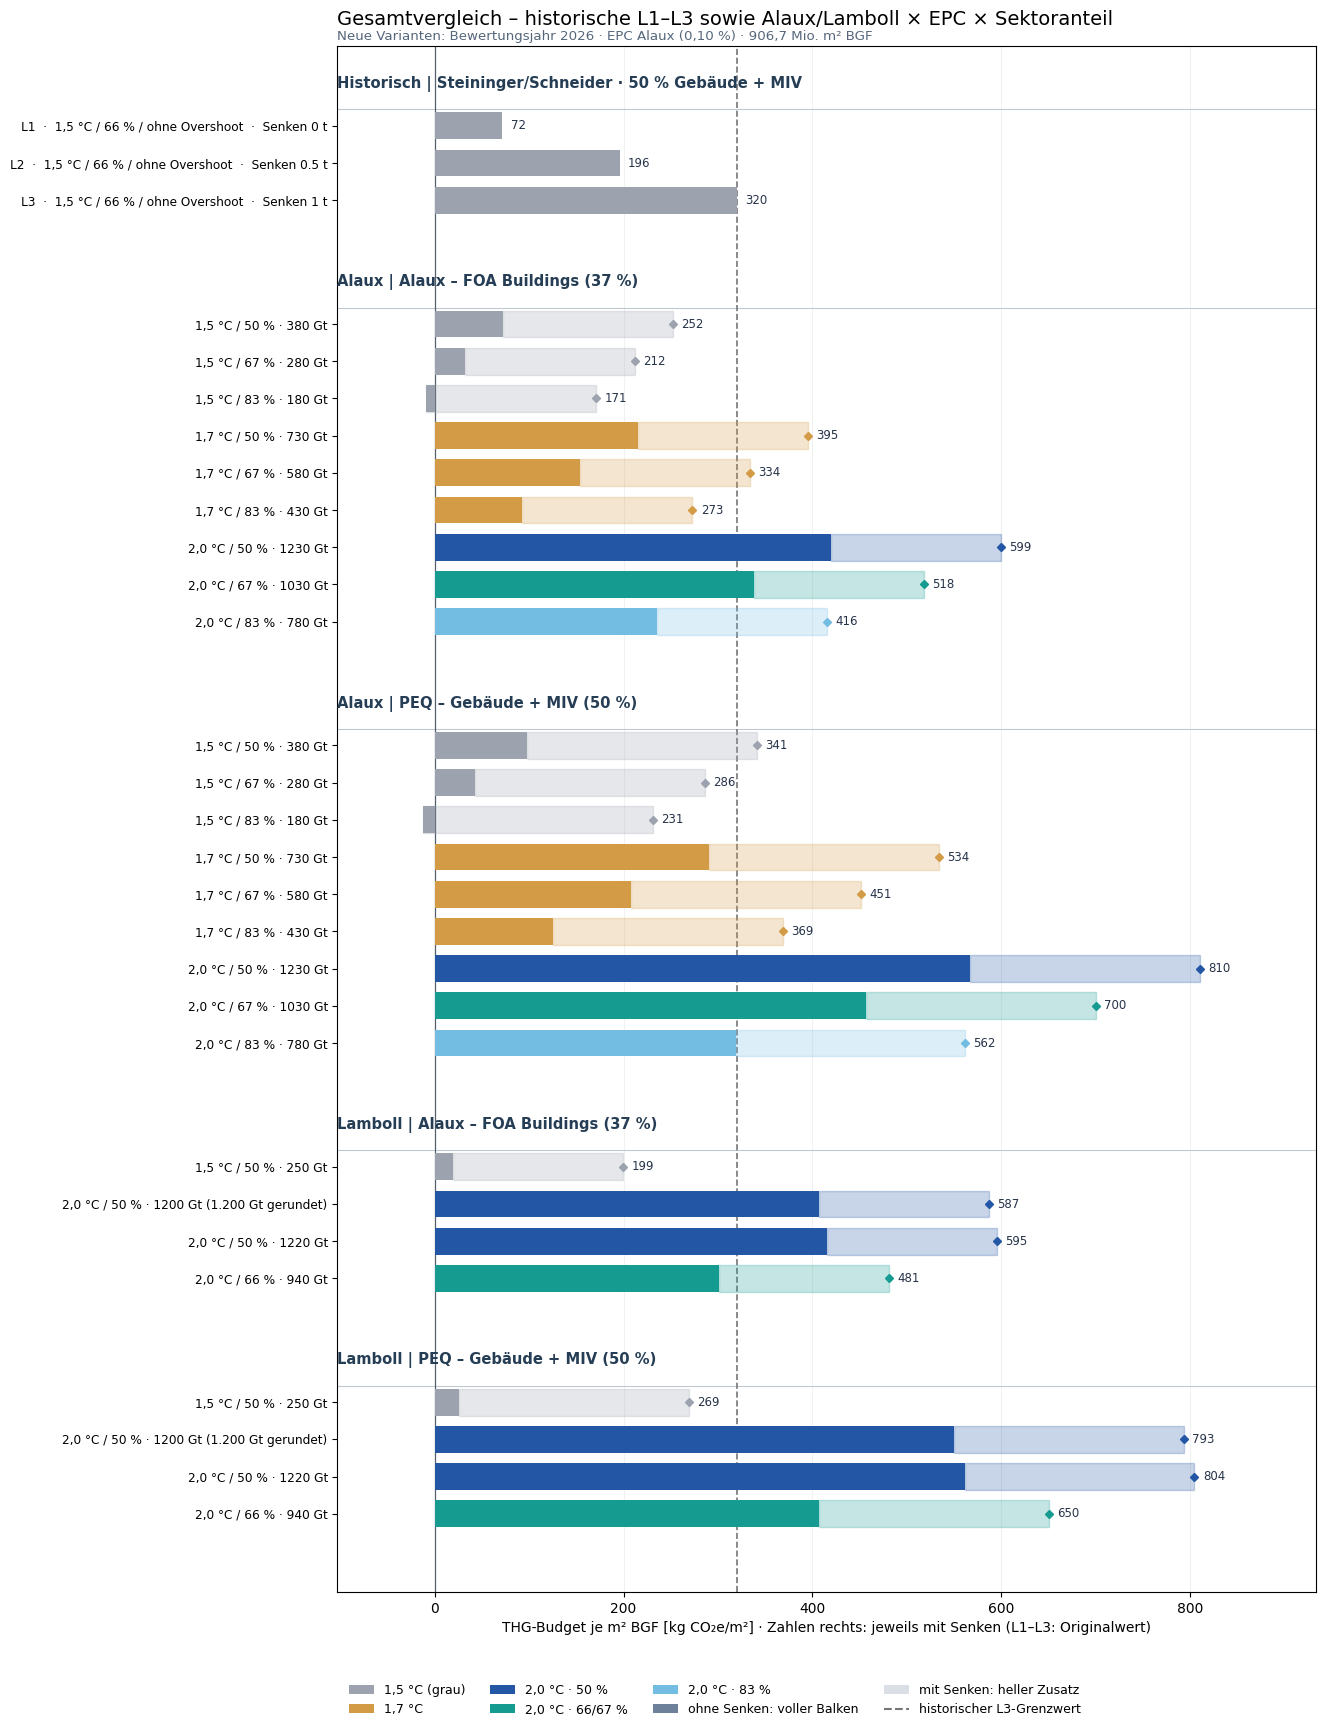

Alle berechneten Szenarien, neue Varianten für 2026 (historische Werte 2025):


,Gruppe,Fall,AT-Budget ab Referenz [Mt],historische Emissionen [Mt],AT-Restbudget [Mt],Sektoranteil [%],Ziel ohne Senken [kg/m²],Ziel mit Senken [kg/m²],Bewertungsjahr
0,Historisch | Steininger/Schneider · 50 % Gebäude + MIV,"L1 · 1,5 °C / 66 % / ohne Overshoot · Senken 0 t",280.0,150.0,130.0,50.0,71.7,71.7,2025
1,Historisch | Steininger/Schneider · 50 % Gebäude + MIV,"L2 · 1,5 °C / 66 % / ohne Overshoot · Senken 0.5 t",280.0,150.0,130.0,50.0,195.8,195.8,2025
2,Historisch | Steininger/Schneider · 50 % Gebäude + MIV,"L3 · 1,5 °C / 66 % / ohne Overshoot · Senken 1 t",280.0,150.0,130.0,50.0,319.8,319.8,2025
3,Lamboll | Alaux – FOA Buildings (37 %),"2,0 °C / 50 % · 1200 Gt (1.200 Gt gerundet)",1200.0,202.4,997.6,37.0,407.1,587.0,2026
4,Lamboll | PEQ – Gebäude + MIV (50 %),"2,0 °C / 50 % · 1200 Gt (1.200 Gt gerundet)",1200.0,202.4,997.6,50.0,550.1,793.3,2026
5,Lamboll | Alaux – FOA Buildings (37 %),"1,5 °C / 50 % · 250 Gt",250.0,202.4,47.6,37.0,19.4,199.4,2026
6,Lamboll | PEQ – Gebäude + MIV (50 %),"1,5 °C / 50 % · 250 Gt",250.0,202.4,47.6,50.0,26.2,269.4,2026
7,Lamboll | Alaux – FOA Buildings (37 %),"2,0 °C / 50 % · 1220 Gt",1220.0,202.4,1017.6,37.0,415.3,595.2,2026
8,Lamboll | PEQ – Gebäude + MIV (50 %),"2,0 °C / 50 % · 1220 Gt",1220.0,202.4,1017.6,50.0,561.1,804.3,2026
9,Lamboll | Alaux – FOA Buildings (37 %),"2,0 °C / 66 % · 940 Gt",940.0,202.4,737.6,37.0,301.0,481.0,2026


In [13]:
#| label: fig-szenarien-sektorvergleich
#| fig-cap: "Gesamtvergleich historischer L-Grenzwerte und neuer globaler Budgetvarianten (37 % FOA vs. 50 % Gebäude + MIV)."
#| fig-width: 14
#| fig-height: 18

# Historische Referenz: 2025; die drei L-Varianten sind bereits unterschiedlich mit Senken belegt.
old = (ref_table.loc[ref_table.budget_id == reference_id]
       .set_index('level').reindex(['L1','L2','L3']))
gesamt_rows = []
for level,r in old.iterrows():
    gesamt_rows.append({
        'Gruppe': 'Historisch | Steininger/Schneider · 50 % Gebäude + MIV',
        'Fall': f'{level}  ·  1,5 °C / 66 % / ohne Overshoot  ·  Senken {r.senken_t_cap_a:g} t',
        'Quelle':'Steininger / Schneider', 'Temperatur':'1,5 °C', 'p [%]':66,
        'global_Gt':np.nan, 'AT_start_Mt':r.start_budget_Mt,
        'UBA_Abzug_Mt':r.historical_deduction_Mt, 'AT_rest_Mt':r.remaining_CO2_budget_Mt,
        'Sektoranteil [%]':100*SECTOR_SHARE, 'Bewertungsjahr':2025,
        'Senken_t':r.senken_t_cap_a,
        'ohne':r.target_kgCO2e_m2_BGF, 'mit':r.target_kgCO2e_m2_BGF,
        'einzelwert':True, 'level':level,
    })

# Beide Quellenstände in beiden Sektorallokationen, für beide Bewertungsjahre.
# 37 % Alaux: FOA Buildings. 50 % PEQ: Gebäude + MIV (nicht gleiche Bilanzgrenze).
for global_case in global_faelle.itertuples(index=False):
    is_alaux = str(global_case.quelle).startswith('Alaux')
    source_name = 'Alaux' if is_alaux else 'Lamboll'
    for sector_label, sector_share in SECTOR_SHARES.items():
        grp = f'{source_name} | {sector_label}'
        for year in EVALUATION_YEARS:
            historical, _ = historical_deduction(int(global_case.referenzjahr), year, MODERN_HISTORY)
            at_start = global_case.global_budget_Gt * 1000 * EPC_METHODS[COMPARISON_EPC_METHOD]
            rest = at_start - historical
            base = allocate_ghg_budget(AllocationInputs(
                rest, POPULATION_MILLION, 0.0, years_remaining(year),
                sector_share, REFERENCE_GFA_MILLION_M2))
            sink = allocate_ghg_budget(AllocationInputs(
                rest, POPULATION_MILLION, 1.0, years_remaining(year),
                sector_share, REFERENCE_GFA_MILLION_M2))
            source_detail = ' (1.200 Gt gerundet)' if 'gerundet' in str(global_case.quelle) else ''
            gesamt_rows.append({
                'Gruppe':grp,
                'Fall':f'{global_case.temperatur} / {int(global_case.wahrscheinlichkeit_pct)} % · {global_case.global_budget_Gt:g} Gt{source_detail}',
                'Quelle':global_case.quelle, 'Temperatur':global_case.temperatur,
                'p [%]':int(global_case.wahrscheinlichkeit_pct),
                'global_Gt':global_case.global_budget_Gt, 'AT_start_Mt':at_start,
                'UBA_Abzug_Mt':historical, 'AT_rest_Mt':rest,
                'Sektoranteil [%]':100*sector_share, 'Bewertungsjahr':year,
                'Senken_t':1.0,
                'ohne':base['target_kgCO2e_m2_BGF'],
                'mit':sink['target_kgCO2e_m2_BGF'],
                'einzelwert':False, 'level':'',
            })

gesamtvergleich = pd.DataFrame(gesamt_rows)
# Die historische Referenz wird nur einmal (2025) gezeigt; die modernen Fälle als 2025/2026.
show = gesamtvergleich.loc[
    (gesamtvergleich['Bewertungsjahr'] == COMPARISON_YEAR) | gesamtvergleich['einzelwert']].copy()
order_groups = [
    'Historisch | Steininger/Schneider · 50 % Gebäude + MIV',
    'Alaux | Alaux – FOA Buildings (37 %)',
    'Alaux | PEQ – Gebäude + MIV (50 %)',
    'Lamboll | Alaux – FOA Buildings (37 %)',
    'Lamboll | PEQ – Gebäude + MIV (50 %)',
]
assert set(show['Gruppe']) == set(order_groups), 'Eine Szenariogruppe fehlt.'

# Quelle → Temperatur → Wahrscheinlichkeit. Die 1,5-°C-Szenarien bleiben grau.
show['temperatur_num'] = (show['Temperatur'].str.replace(',', '.', regex=False)
                            .str.extract(r'(\d+\.?\d*)')[0].astype(float))
show['sortkey'] = show['temperatur_num']*1000 + show['p [%]']
ordered = []
for group in order_groups:
    groupdata = show.loc[show['Gruppe'] == group]
    if group.startswith('Historisch'):
        groupdata = groupdata.set_index('level').reindex(['L1','L2','L3']).reset_index()
    else:
        groupdata = groupdata.sort_values(['sortkey','global_Gt'], ascending=[True,True])
    ordered.extend(groupdata.to_dict('records'))

# Ein einziges, durchgehendes Diagramm mit farbiger Codierung.
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(14.5, 18.3))
ypositions, ylabels, headings, plot_rows = [], [], [], []
y = 0.0
for group in order_groups:
    headings.append((y, group))
    y += 1.15
    for r in ordered:
        if r['Gruppe'] != group: continue
        ypositions.append(y)
        ylabels.append(r['Fall'])
        plot_rows.append(r)
        y += 0.86
    y += 0.85

minval = min(0, *(r['ohne'] for r in plot_rows))
maxval = max(r['mit'] for r in plot_rows)
spread = max(100, maxval-minval)
ax.set_xlim(min(minval-spread*.11, -35), maxval+spread*.15)
for i, (pos,r) in enumerate(zip(ypositions, plot_rows)):
    color = scenario_color(r['Temperatur'], r['p [%]'])
    ax.barh(pos, r['ohne'], height=.62, color=color, zorder=3)
    if not r['einzelwert']:
        delta = r['mit'] - r['ohne']
        ax.barh(pos, delta, left=r['ohne'], height=.62,
                color=color, alpha=.25, edgecolor=color, linewidth=1.0, zorder=3)
        ax.plot(r['mit'],pos,marker='D',markersize=4,color=color,zorder=4)
        label_value=r['mit']
    else:
        label_value=r['ohne']
    ax.annotate(f'{label_value:,.0f}', (label_value,pos), xytext=(6 if label_value>=0 else -6,0),
                textcoords='offset points',va='center',ha='left' if label_value>=0 else 'right',
                fontsize=8.5, color='#253248')

ax.set_yticks(ypositions, ylabels, fontsize=8.7)
ax.set_ylim(y+0.1,-.7)
for yy,group in headings:
    # Gruppenüberschriften liegen auf einer eigenen freien Zeile.
    ax.text(0.0, yy, group, transform=ax.get_yaxis_transform(),
            ha='left',va='top',fontsize=10.6,fontweight='bold',color='#263e55')
    ax.axhline(yy+.77,color='#bdc7d0',lw=.75,zorder=1)
ax.axvline(0,color='#55606c',lw=.9)
ax.axvline(320,color='#767676',linestyle='--',lw=1.2,label='Historische L3 = 320')
ax.set_xlabel('THG-Budget je m² BGF [kg CO₂e/m²] · Zahlen rechts: jeweils mit Senken (L1–L3: Originalwert)',fontsize=10)
ax.set_title('Gesamtvergleich – historische L1–L3 sowie Alaux/Lamboll × EPC × Sektoranteil',fontsize=14,loc='left',pad=15)
ax.text(.0,1.004,f'Neue Varianten: Bewertungsjahr {COMPARISON_YEAR} · {COMPARISON_EPC_METHOD} · 906,7 Mio. m² BGF',
        transform=ax.transAxes,ha='left',fontsize=9.6,color='#56677c')
ax.grid(axis='x',alpha=.17); ax.grid(axis='y',visible=False); ax.set_axisbelow(True)
legend = [Patch(facecolor='#9ca3af',label='1,5 °C (grau)'),
          Patch(facecolor='#d39b45',label='1,7 °C'),
          Patch(facecolor='#2456a6',label='2,0 °C · 50 %'),
          Patch(facecolor='#169b91',label='2,0 °C · 66/67 %'),
          Patch(facecolor='#74bde2',label='2,0 °C · 83 %'),
          Patch(facecolor='#6d819b',label='ohne Senken: voller Balken'),
          Patch(facecolor='#6d819b',alpha=.25,label='mit Senken: heller Zusatz'),
          Line2D([0],[0],color='#767676',ls='--',label='historischer L3-Grenzwert'),
        ]
ax.legend(handles=legend,loc='upper left',bbox_to_anchor=(0,-.052),ncol=4,fontsize=9,frameon=False)
fig.subplots_adjust(left=.31,right=.985,top=.945,bottom=.10)
plt.show()

print('Alle berechneten Szenarien, neue Varianten für',COMPARISON_YEAR,
      '(historische Werte 2025):')
cols = ['Gruppe','Fall','AT_start_Mt','UBA_Abzug_Mt','AT_rest_Mt',
        'Sektoranteil [%]','ohne','mit','Bewertungsjahr']
display(show[cols].rename(columns={
    'AT_start_Mt':'AT-Budget ab Referenz [Mt]',
    'UBA_Abzug_Mt':'historische Emissionen [Mt]',
    'AT_rest_Mt':'AT-Restbudget [Mt]',
    'ohne':'Ziel ohne Senken [kg/m²]',
    'mit':'Ziel mit Senken [kg/m²]'}).round(1).reset_index(drop=True))


::: {.callout-tip title="Interpretation des Vergleichs"}
Der sektorale Faktor ist nun **direkt im Diagramm** sichtbar. Bei gleichem Ausgangsbudget skaliert der flächenbezogene Zielwert mit dem Sektoranteil (37 % beziehungsweise 50 %). 1,5 °C wird grau dargestellt, um die bevorzugte Diskussion der 1,7- und 2-°C-Fälle nicht zu überlagern. Die Farbgebung ist eine **Visualisierungsentscheidung**, keine Änderung der wissenschaftlichen Gültigkeit der 1,5-°C-Budgets.
:::

::: {.callout-warning title="Zu entscheidende Annahmen" collapse="true"}
- **FOA Buildings / Gebäude + MIV:** 37 % und 50 % sind unterschiedliche Abgrenzungen. Eine verbindliche Neuzuteilung ist offen.
- **EPC:** Hauptvergleich 0,10 % nach Alaux; alternativ der Anteil Österreich/Welt im Jahr 2023.
- **Historische Emissionen:** UBA-CO₂e-Näherung anstelle einer harmonisierten CO₂-only-Reihe.
- **Senken:** 0 versus 1 t CO₂e/(Person·a), verbleibende Laufzeit bis 2075; mögliche Doppelzählung ist offen.
- **Alaux:** Die aus `Globalbudget × EPC × 37 %` berechneten Werte sind eine konsistente *Modellübertragung*; sie werden nicht als exakte publizierte österreichische FOA-Budgets bezeichnet.
:::


## 8. Senkenjahre und BGF-Alternativen

In [14]:
sink_years=pd.DataFrame({'bewertungsjahr':EVALUATION_YEARS,
                         'senkenjahre':[years_remaining(y) for y in EVALUATION_YEARS]})
sink_years['senken_bei_1t_Mt']=POPULATION_MILLION*sink_years.senkenjahre
sink_years['methode']=HORIZON_POLICY
display(sink_years)

,bewertungsjahr,senkenjahre,senken_bei_1t_Mt,methode
0,2025,50,450.0,fixed_end
1,2026,49,441.0,fixed_end


,datenstand,beschreibung,jahr,BGF_Mio_m2,NGF_Mio_m2,quelle,hinweis
0,statistik_2021,Statistikbezug / GFZ-Hochrechnung,2021,1058.935,847.100,S2,andere Abgrenzung
1,pool_today,"Building-Sector Pool, heute",offen,1112.341,889.873,S2,Typenflächen
2,pool_2040,"Building-Sector Pool, Entwicklung 2040",2040,1126.579,901.263,S2,keine automatische THG-Änderung
3,thg_reference,Zielbestand 2040 für THG-Allokation,2040,906.700,NaN,S1-A1,historische Kalibrierung


,beschreibung,BGF_Mio_m2,L3_kg_m2_bei_unveraendertem_Sektorbudget
0,Statistikbezug / GFZ-Hochrechnung,1058.935,273.860058
1,"Building-Sector Pool, heute",1112.341,260.711419
2,"Building-Sector Pool, Entwicklung 2040",1126.579,257.416479
3,Zielbestand 2040 für THG-Allokation,906.700,319.841182


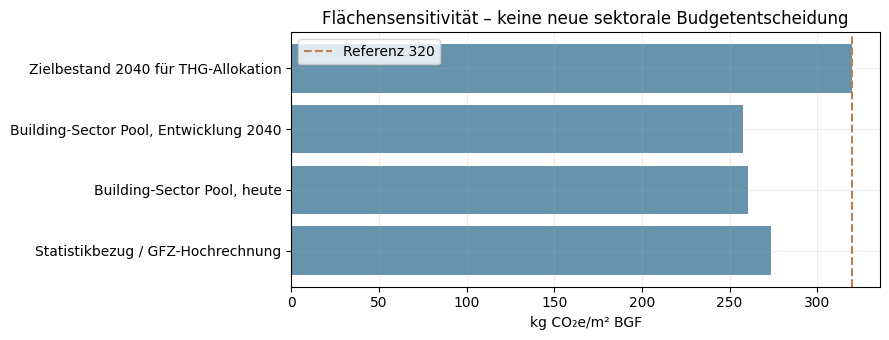

In [15]:
floor_areas=pd.DataFrame([
    ('statistik_2021','Statistikbezug / GFZ-Hochrechnung','2021',1058.935,847.1,'S2','andere Abgrenzung'),
    ('pool_today','Building-Sector Pool, heute','offen',1112.341,889.873,'S2','Typenflächen'),
    ('pool_2040','Building-Sector Pool, Entwicklung 2040','2040',1126.579,901.263,'S2','keine automatische THG-Änderung'),
    ('thg_reference','Zielbestand 2040 für THG-Allokation','2040',906.7,np.nan,'S1-A1','historische Kalibrierung'),
],columns=['datenstand','beschreibung','jahr','BGF_Mio_m2','NGF_Mio_m2','quelle','hinweis'])
display(floor_areas)
base=calculate_scenario(reference_id,2025,1.0,REPRODUCTION_HISTORY)
areas=floor_areas[['beschreibung','BGF_Mio_m2']].copy()
areas['L3_kg_m2_bei_unveraendertem_Sektorbudget']=1000*base['sector_budget_Mt']/areas.BGF_Mio_m2
display(areas)
fig,ax=plt.subplots(figsize=(9,3.5))
ax.barh(areas.beschreibung,areas.L3_kg_m2_bei_unveraendertem_Sektorbudget,color='#6793ad')
ax.axvline(320,ls='--',color='#bd804f',label='Referenz 320')
ax.set(xlabel='kg CO₂e/m² BGF',title='Flächensensitivität – keine neue sektorale Budgetentscheidung')
ax.legend();plt.tight_layout();plt.show()

## 9. Sensitivitätsanalyse – zentrale Parameter

,Stellgröße,Variante,Wert,Zielwert [kg CO₂e/m² BGF],Änderung zu Basis [kg/m²]
0,Ausgangswert,Basis,"1.200 Gt / EPC 0,10 %",793.3,0.0
1,Globalbudget,Lamboll präzise,1.220 Gt,804.3,11.0
2,Globalbudget,Alaux,1.230 Gt,809.9,16.5
3,EPC,niedriger,"0,09 %",727.1,-66.2
4,EPC,höher,"0,11 %",859.5,66.2
5,Sektoranteil,niedriger,40 %,634.6,-158.7
6,Sektoranteil,höher,60 %,952.0,158.7
7,BGF,Statistikmodell 2021,"1.058,935 Mio. m²",679.3,-114.0
8,BGF,Pool 2040,"1.126,579 Mio. m²",638.5,-154.8
9,Senken,L1,0 t/(Person a),550.1,-243.2


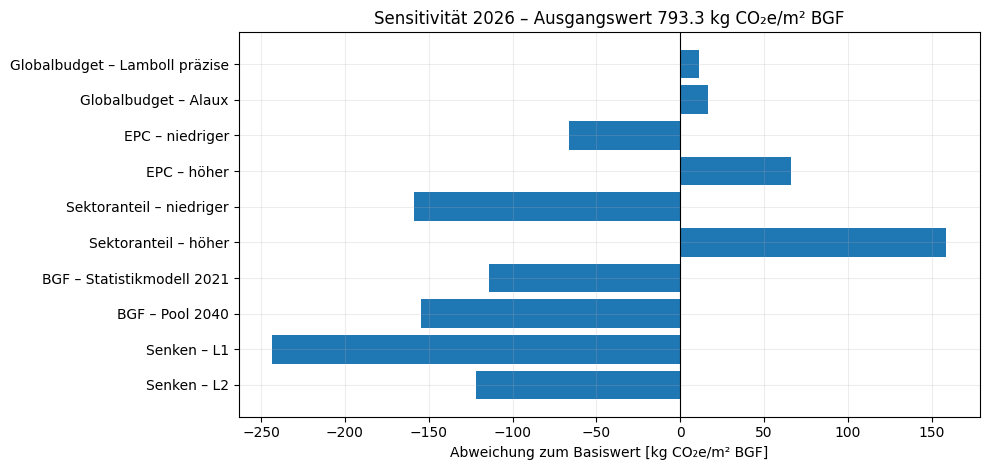

In [16]:
# Jeweils nur eine Annahme gegenüber dem Basisfall für 2026 ändern.
# Globale Budgets in Gt CO₂, alle übrigen Budgets in Mt CO₂.
from itertools import chain

basisjahr = 2026
abzug, _ = historical_deduction(2023, basisjahr, MODERN_HISTORY)

def zielwert_variante(global_Gt=LAMBOLL_20_50_REPORTED_ROUNDED_Gt,
                      epc=EPC_AT_POPULATION_SHARE,
                      sektor=SECTOR_SHARE, bgf=REFERENCE_GFA_MILLION_M2,
                      senken=1.0, bevoelkerung=POPULATION_MILLION):
    budget_at = global_Gt * 1000 * epc
    return allocate_ghg_budget(AllocationInputs(
        budget_at - abzug, bevoelkerung, senken,
        years_remaining(basisjahr), sektor, bgf))['target_kgCO2e_m2_BGF']

varianten = [
    ('Ausgangswert', 'Basis', '1.200 Gt / EPC 0,10 %', {}),
    ('Globalbudget', 'Lamboll präzise', '1.220 Gt', {'global_Gt': 1220.0}),
    ('Globalbudget', 'Alaux', '1.230 Gt', {'global_Gt': 1230.0}),
    ('EPC', 'niedriger', '0,09 %', {'epc': 0.0009}),
    ('EPC', 'höher', '0,11 %', {'epc': 0.0011}),
    ('Sektoranteil', 'niedriger', '40 %', {'sektor': 0.40}),
    ('Sektoranteil', 'höher', '60 %', {'sektor': 0.60}),
    ('BGF', 'Statistikmodell 2021', '1.058,935 Mio. m²', {'bgf': 1058.935}),
    ('BGF', 'Pool 2040', '1.126,579 Mio. m²', {'bgf': 1126.579}),
    ('Senken', 'L1', '0 t/(Person a)', {'senken': 0.0}),
    ('Senken', 'L2', '0,5 t/(Person a)', {'senken': 0.5}),
]
basis_l3=zielwert_variante()
sens=pd.DataFrame([{'Stellgröße':typ,'Variante':name,'Wert':wert,
                    'Zielwert [kg CO₂e/m² BGF]':zielwert_variante(**params)}
                   for typ,name,wert,params in varianten])
sens['Änderung zu Basis [kg/m²]'] = sens['Zielwert [kg CO₂e/m² BGF]'] - basis_l3
display(sens.round(1))
fig, ax=plt.subplots(figsize=(10,4.8))
plot_df = sens.iloc[1:].copy()
labels = plot_df['Stellgröße']+' – '+plot_df['Variante']
ax.barh(labels, plot_df['Änderung zu Basis [kg/m²]'])
ax.axvline(0, lw=.8, color='black')
ax.invert_yaxis()
ax.set(xlabel='Abweichung zum Basiswert [kg CO₂e/m² BGF]',
       title=f'Sensitivität 2026 – Ausgangswert {basis_l3:.1f} kg CO₂e/m² BGF')
plt.tight_layout();plt.show()

## 10. Absenkpfade (illustrativ, nicht Teil der Budgetallokation)

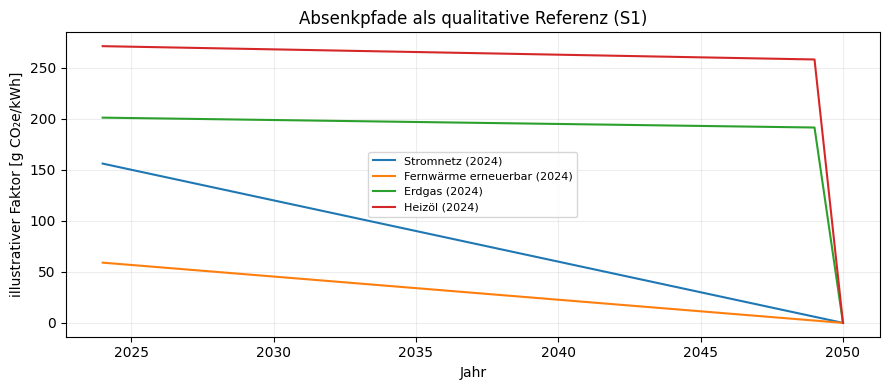

In [17]:
carrier_start={'Stromnetz (2024)':156,'Fernwärme erneuerbar (2024)':59,
               'Erdgas (2024)':201,'Heizöl (2024)':271}
fig,ax=plt.subplots(figsize=(9,4))
for name,g in carrier_start.items():
    yrs=np.arange(2024,2051)
    if 'Erdgas' in name or 'Heizöl' in name:
        path=np.where(yrs<2050,g*(1-.05*(yrs-2024)/26),0)
    else: path=g*np.maximum(0,(2050-yrs)/26)
    ax.plot(yrs,path,label=name)
ax.set(xlabel='Jahr',ylabel='illustrativer Faktor [g CO₂e/kWh]',title='Absenkpfade als qualitative Referenz (S1)')
ax.legend(fontsize=8);plt.tight_layout();plt.show()

## 11. Rechenkontrollen

In [18]:
# Grundgleichungen für alle budgetierbaren Szenarien
assert budgets.budget_id.is_unique
assert not history.duplicated(['jahr','reihe']).any()
assert math.isclose(epc_allocated_budget_Mt,
    LAMBOLL_20_50_REPORTED_ROUNDED_Gt * 1000 * EPC_AT_POPULATION_SHARE)
for row in ref_table.itertuples():
    assert math.isfinite(row.target_kgCO2e_m2_BGF)
for year in EVALUATION_YEARS:
    work=calculate_scenario(SELECTED_BUDGET_ID,year,SINK_LEVELS['L3'],MODERN_HISTORY)
    assert math.isclose(work['remaining_CO2_budget_Mt'],
        work['start_budget_Mt']-work['historical_deduction_Mt'])
# Historische L3-Reproduktion nur mit unveränderten historischen Parametern prüfen.
if (math.isclose(POPULATION_MILLION,9) and math.isclose(SECTOR_SHARE,.5) and
    math.isclose(REFERENCE_GFA_MILLION_M2,906.7) and ASSESSMENT_END_YEAR==2075 and
    HORIZON_POLICY=='fixed_end'):
    check=calculate_scenario('STEIN2022_15_NO_66',2025,1.0,REPRODUCTION_HISTORY)
    assert round(check['target_kgCO2e_m2_BGF'])==320
    print('Historische L3-Referenz 320 kg/m² reproduziert.')
else:
    print('Historische Referenzparameter verändert; 320er-Regression übersprungen.')
print('Schnellprüfungen bestanden.')
# Zusätzliche Kontrollgleichungen für die Sektorvergleichsfassung:
assert set(SECTOR_SHARES.values()) == {0.37, 0.50}
modern = gesamtvergleich[~gesamtvergleich.einzelwert]
assert len(modern) == len(global_faelle) * len(EVALUATION_YEARS) * len(SECTOR_SHARES)
for z in modern.groupby(['Quelle','Temperatur','p [%]','global_Gt','Bewertungsjahr']):
    g = z[1].sort_values('Sektoranteil [%]')
    assert len(g) == 2
    for v in ['ohne','mit']:
        if abs(g.iloc[0][v]) > 1e-9:
            assert math.isclose(g.iloc[1][v] / g.iloc[0][v], 50/37, rel_tol=1e-10)
print('Sektorvergleich (37 % / 50 %) und Variantenanzahl geprüft.')


Historische L3-Referenz 320 kg/m² reproduziert.
Schnellprüfungen bestanden.
Sektorvergleich (37 % / 50 %) und Variantenanzahl geprüft.


## Offene Diskussionspunkte

- **EPC:** 0,10 % (Alaux, ursprünglich *FOA Buildings*) versus tatsächlicher Anteil 2023 (World Bank); beide als Modellalternativen.
- **Emissionsabzug:** Gesamt-THG in Mt CO₂e statt CO₂-only; 2025 vorläufig.
- **Senken:** zusätzlich 0 oder 1 t CO₂e/(Person·a) – gesondert zu prüfen, ob diese Annahme mit einem globalen Netto-CO₂-Budget konsistent ist.
- **PEQ-Allokation:** 50 % Gebäude + MIV, 906,7 Mio. m² BGF, 9 Mio. Personen, Senken 0–1 t/(Person·a).
- **Zeithorizont:** festes Endjahr 2075 oder rollierende 50 Jahre.
- **Datenvergleich:** gerundetes Lamboll-Budget 1.200 Gt gegenüber 1.220 Gt (Lamboll detailliert) und 1.230 Gt (Alaux).